
# Figures for *Artificial Simulation of Neuronal Evolution*

This notebook is meant to **recreate and extend the figures** used in the article.
It covers three groups of visuals:

1. **Recreations of the article figures** (distributions, box plots, and schematic diagrams).
2. **Brain Explorer–style heatmaps**, using slice-based visualizations with colorbars.
3. **Additional article candidates**, especially for the spatial field $A$ and the connection affinity $H$.

The figures are intentionally a bit more polished than the original ones, but the underlying formulas follow the current theory in `article.tex`.

> **Note.** Some schematic diagrams below are *stylized recreations* rather than pixel-by-pixel reproductions of the PDF. The statistical plots and heatmaps, however, are generated directly from the mathematical definitions.



## Figure catalog (stable descriptive names)

### Core article visualizations
- Slice structure of the brain tensor
- Distributions of $F_\beta$
- Box plots of relative differences of $F_\beta$
- Distributions of $G_{\delta_1,\delta_2}$
- Distribution of $N_{\max}$
- Distribution of $S(y)$
- Local rectangular connection region
- Slice-interleaved input/output ordering
- Saturation function $\sigma$
- Threshold distribution
- Local 6-neighborhood in 3D
- Decay distribution $e^{-12/D}$
- Retention factor distribution $M$
- Structural plasticity threshold distribution $P$
- Input influence factor distribution $1 + \sin(G_{1,1})$
- Timeline of updates affecting existing connections
- Conceptual GPU/brain organization
- Schematic neuronal dynamics / compute-shader motivation

### Additional visualizations for the article
- Heatmaps of $A$, $T$, $M$, $Q$, $R$, and polarity by slice
- Heatmaps of the outgoing $H$ landscape for a fixed source neuron
- 3D scatter / voxel-like views of the field $A$
- Positive/negative connection-affinity masks derived from $H$
- Scatter plots relating $A$ to $T$, $M$, $Q$, and decay rate

### Independent-gene comparisons (new)
- A: six independent genomes on a fixed slice, plus six related genomes with controlled mutations
- H: six independent connections genes with a fixed source, plus controlled mutations with the source fixed
- Identical `[-1, 1]` color scales within every comparison; source coordinates are marked on H maps


In [1]:

from pathlib import Path
import math
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

SEED = 1234
rng = np.random.default_rng(SEED)

OUTPUT_DIR = Path("generated_article_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# Display and export resolutions are deliberately independent.
# Lower PREVIEW_DPI keeps figures readable in a Jupyter browser window;
# EXPORT_DPI preserves high resolution for figures saved for the article.
PREVIEW_DPI = 100
EXPORT_DPI = 220
SAVE_FIGURES = True
SHOW_FIGURES = True

plt.rcParams.update({
    "figure.dpi": PREVIEW_DPI,
    "savefig.dpi": EXPORT_DPI,
    "figure.figsize": (8, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})


def save_fig(fig, name: str):
    path = OUTPUT_DIR / f"{name}.png"
    if SAVE_FIGURES:
        fig.savefig(path, dpi=EXPORT_DPI, bbox_inches="tight")
    return path

print(f"Output directory: {OUTPUT_DIR.resolve()}")
print(f"Jupyter preview: {PREVIEW_DPI} DPI | Article export: {EXPORT_DPI} DPI")


Output directory: D:\Computacao\Godot\Games\Neurons\article\generated_article_figures
Jupyter preview: 100 DPI | Article export: 220 DPI


**Figure sizing.** The notebook renders previews at **100 DPI** so individual figures fit comfortably inside Jupyter. Saved PNG files are exported at **220 DPI** and retain print-quality detail. You can change `PREVIEW_DPI` and `EXPORT_DPI` independently in the setup cell. Multi-panel figures are intentionally somewhat larger than individual plots.


## Model utilities

The implementation below follows the article and the current GPU project logic:

- $W(t)=
\sqrt{1+t}$
- $U(x_t)=1+x_t$
- $F_\beta(x)=\sum_t \sqrt{1+t}\,\beta^{x_t}$
- $G_{\delta_1,\delta_2}(x)=\sum_t \sin(1+t)\sin(1+x_t)^{\delta_1}\cos(1+x_t)^{\delta_2}$
- $A_{i,j,k}(x)$ uses the fixed spatial scale $L=16$ and the mode frequencies $\omega_r=\sqrt{r+1}$
- $H_{i,j,k}(u,v,w,x)$ uses the compressed coefficient form already present in the project code


In [2]:

# ---------- basic gene utilities ----------

def random_genes(num_samples: int, p: int, rng=None):
    rng = np.random.default_rng(SEED) if rng is None else rng
    return rng.integers(0, 4, size=(num_samples, p), dtype=np.int64)


def W(t):
    return np.sqrt(1.0 + np.asarray(t))


def U(x):
    return 1.0 + np.asarray(x)


def alpha_digit(x):
    return 2.0 * np.asarray(x) / 3.0 - 1.0


# ---------- scalar feature families ----------

def F_beta(gene, beta: float):
    gene = np.asarray(gene)
    weights = W(np.arange(gene.shape[-1]))
    if gene.ndim == 1:
        return np.sum(weights * (beta ** gene))
    return np.sum(weights[None, :] * (beta ** gene), axis=1)


def G_value(gene, delta1: int, delta2: int):
    gene = np.asarray(gene)
    weights = np.sin(1.0 + np.arange(gene.shape[-1]))
    if gene.ndim == 1:
        return np.sum(weights * (np.sin(1.0 + gene) ** delta1) * (np.cos(1.0 + gene) ** delta2))
    return np.sum(weights[None, :] * (np.sin(1.0 + gene) ** delta1) * (np.cos(1.0 + gene) ** delta2), axis=1)


def S_value(gene):
    return np.clip((1.0 - np.sqrt(np.abs(np.cos(G_value(gene, 0, 1))))) / 10.0, 0.0, 0.1)


def beta_from_gene(gene, I: int, J: int):
    gene = np.asarray(gene)
    weights = W(np.arange(gene.shape[-1]))
    weighted_sum = np.sum(weights * gene)
    max_sum = np.sum(3.0 * weights)
    scale = ((I * J) / 16.0) ** (1.0 / 3.0)
    return 1.0 + (weighted_sum / max_sum) * scale


def Nmax_fixed_beta(gene, beta: float = 4.0, eta: float = 1.0):
    return max(1, int(np.floor(eta * F_beta(gene, beta))))


# ---------- spatial field A ----------

def A_volume(gene, dims, spatial_scale: float = 16.0):
    gene = np.asarray(gene, dtype=float)
    I, J, K = dims
    p = gene.size
    n = round(p ** (1.0 / 3.0))
    if n ** 3 != p:
        raise ValueError("A_volume expects p = n^3.")

    a = np.arange(I, dtype=float) / spatial_scale
    b = np.arange(J, dtype=float) / spatial_scale
    c = np.arange(K, dtype=float) / spatial_scale

    basis_a = np.array([np.cos(np.pi * np.sqrt(r + 1.0) * a) for r in range(n)])
    basis_b = np.array([np.cos(np.pi * np.sqrt(s + 1.0) * b) for s in range(n)])
    basis_c = np.array([np.cos(np.pi * np.sqrt(q + 1.0) * c) for q in range(n)])

    coeffs = alpha_digit(gene).reshape(n, n, n)
    acc = np.zeros((I, J, K), dtype=float)

    for r in range(n):
        for s in range(n):
            for q in range(n):
                acc += coeffs[r, s, q] * basis_a[r][:, None, None] * basis_b[s][None, :, None] * basis_c[q][None, None, :]

    return np.tanh(acc / np.sqrt(p))


# ---------- auxiliary H ----------

def H_coefficients(gene):
    gene = np.asarray(gene)
    weights = W(np.arange(gene.size))
    coeffs = np.zeros(4, dtype=float)
    for digit in range(4):
        coeffs[digit] = weights[gene == digit].sum()
    return coeffs * (4.0 / weights.sum())


def H_value(A_src: float, A_tgt: float, coefficients):
    c0, c1, c2, c3 = coefficients
    return np.sin(
        3.0 * np.pi / 8.0
        + c0 * (np.sin(A_src) + np.cos(A_tgt))
        + c1 * (np.sin(2.0 * A_src) + np.cos(2.0 * A_tgt))
        + c2 * (np.sin(3.0 * A_src) + np.cos(3.0 * A_tgt))
        + c3 * (np.sin(4.0 * A_src) + np.cos(4.0 * A_tgt))
    )


def H_map(A_vol, source, coefficients):
    i, j, k = source
    A_src = A_vol[i, j, k]
    return H_value(A_src, A_vol, coefficients)


# ---------- derived neuronal quantities ----------

def sigma(s, kappa=4.0):
    return 1.0 - np.exp(-np.asarray(s) / kappa)


def threshold_from_A(A):
    return (1.0 + A) / 2.0


def retention_from_A(A):
    return (1.0 - np.exp(-1.0 - A)) / (1.0 - np.exp(-2.0))


def decay_factor_from_A(A):
    D = 1.5 + A
    return np.exp(-12.0 / D)


def polarity_from_A(A):
    a0 = A[(0,) * A.ndim]
    return np.where(A < a0, -1, 1)


def plasticity_threshold(gene):
    return 1.75 + 0.25 * np.cos(G_value(gene, 1, 1))


def input_influence_factor(gene):
    return 1.0 + np.sin(G_value(gene, 1, 1))


def Q_from_A(A):
    return (1.0 + A) / 2.0


def R_from_A(A):
    return np.array(A, copy=True)


In [3]:

# ---------- plotting helpers ----------

def plot_hist_family(data_by_label, bins=70, title="", xlabel="", ylabel="Frequency", ncols=2, figsize=None):
    labels = list(data_by_label.keys())
    n = len(labels)
    nrows = int(np.ceil(n / ncols))
    if figsize is None:
        figsize = (3.8 * ncols, 3.3 * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, label in zip(axes, labels):
        ax.hist(np.asarray(data_by_label[label]), bins=bins)
        ax.set_title(str(label))
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
    for ax in axes[len(labels):]:
        ax.axis("off")
    fig.suptitle(title, y=1.02, fontsize=15, fontweight="bold")
    fig.tight_layout()
    return fig


def boxplot_by_distance(distances, rel_diffs, max_distance=None, title="", figsize=(10.8, 4.3), min_count=15):
    distances = np.asarray(distances)
    rel_diffs = np.asarray(rel_diffs)
    unique = np.unique(distances)
    if max_distance is not None:
        unique = unique[unique <= max_distance]
    labels = []
    series = []
    for d in unique:
        vals = rel_diffs[distances == d]
        if vals.size >= min_count:
            labels.append(int(d))
            series.append(vals)
    fig, ax = plt.subplots(figsize=figsize)
    ax.boxplot(series, labels=labels, showfliers=False)
    ax.set_title(title)
    ax.set_xlabel(r"L1 distance $d(x,y)$")
    ax.set_ylabel(r"Relative difference $|F_\beta(x)-F_\beta(y)| / F_\beta(x)$")
    if len(labels) > 25:
        step = max(1, len(labels) // 18)
        for idx, tick in enumerate(ax.get_xticklabels()):
            tick.set_visible(idx % step == 0)
    fig.tight_layout()
    return fig


def sample_relative_differences(p, beta, num_pairs=40000, seed=0):
    local_rng = np.random.default_rng(seed)
    x = random_genes(num_pairs, p, local_rng)
    y = random_genes(num_pairs, p, local_rng)
    d = np.abs(x - y).sum(axis=1)
    fx = F_beta(x, beta)
    fy = F_beta(y, beta)
    rel = np.abs(fx - fy) / np.maximum(fx, 1e-12)
    return d, rel


def heatmap_grid(volume, title, cmap="coolwarm", max_cols=4, colorbar_label="Value", vmin=None, vmax=None):
    I, J, K = volume.shape
    cols = min(max_cols, K)
    rows = int(np.ceil(K / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.0 * cols, 3.1 * rows), squeeze=False, constrained_layout=True)
    if vmin is None:
        vmin = np.nanmin(volume)
    if vmax is None:
        vmax = np.nanmax(volume)
    im = None
    for k in range(K):
        r = k // cols
        c = k % cols
        ax = axes[r, c]
        im = ax.imshow(volume[:, :, k].T, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
        ax.set_title(f"Slice k={k}")
        ax.set_xlabel("i")
        ax.set_ylabel("j")
    for idx in range(K, rows * cols):
        axes[idx // cols, idx % cols].axis("off")
    fig.suptitle(title, y=1.02, fontsize=15, fontweight="bold")
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.92)
    cbar.set_label(colorbar_label)
    return fig


def annotate_panel(ax, text, xy, width, height, fontsize=10, box_alpha=0.08, edge_alpha=0.35):
    rect = patches.FancyBboxPatch(
        xy, width, height,
        boxstyle="round,pad=0.02,rounding_size=0.02",
        linewidth=1.0,
        edgecolor=(0, 0, 0, edge_alpha),
        facecolor=(0, 0, 0, box_alpha),
        transform=ax.transAxes,
    )
    ax.add_patch(rect)
    ax.text(xy[0] + width/2, xy[1] + height/2, text, transform=ax.transAxes,
            ha="center", va="center", fontsize=fontsize)


def heatmap_first_axis_cuts(volume, i_indices, title, *, cmap="coolwarm", colorbar_label="Value", vmin=-1, vmax=1, max_cols=4):
    """Plot 2D cross-sections volume[i, :, :] with i fixed; horizontal=j, vertical=k."""
    volume = np.asarray(volume)
    if volume.ndim != 3:
        raise ValueError("Expected a three-dimensional field (I, J, K).")
    I, J, K = volume.shape
    i_indices = np.asarray(i_indices, dtype=int)
    if i_indices.ndim != 1 or i_indices.size == 0 or np.any((i_indices < 0) | (i_indices >= I)):
        raise ValueError("i_indices must contain valid first-axis indices.")

    cols = min(max_cols, len(i_indices))
    rows = int(np.ceil(len(i_indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.7 * cols, 2.85 * rows),
                             squeeze=False, constrained_layout=True)
    for panel, i in enumerate(i_indices):
        ax = axes.flat[panel]
        im = ax.imshow(volume[i, :, :].T, origin="lower", cmap=cmap,
                       vmin=vmin, vmax=vmax, aspect="auto", interpolation="nearest")
        ax.set_title(f"i = {i}")
        ax.set_xlabel("j")
        ax.set_ylabel("k")
        ax.set_yticks(np.unique(np.linspace(0, K - 1, min(K, 5)).astype(int)))
        ax.grid(False)
    for ax in axes.flat[len(i_indices):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=15, fontweight="bold")
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.9, pad=0.015)
    cbar.set_label(colorbar_label)
    return fig


## Structure of slices in the model

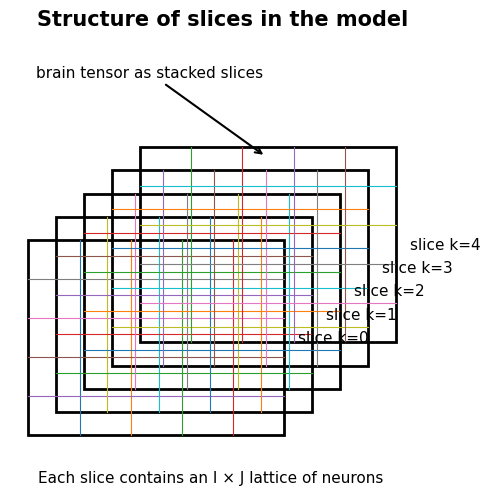

WindowsPath('generated_article_figures/slices_structure.png')

In [4]:

fig = plt.figure(figsize=(7.6, 5.1))
ax = fig.add_subplot(111)
ax.set_aspect('equal')
ax.axis('off')

num_slices = 5
base_x, base_y = 0.12, 0.18
w, h = 0.55, 0.42
dx, dy = 0.06, 0.05

for k in range(num_slices):
    x = base_x + k * dx
    y = base_y + k * dy
    rect = patches.Rectangle((x, y), w, h, fill=False, linewidth=2.0)
    ax.add_patch(rect)
    for gx in np.linspace(x + w/5, x + 4*w/5, 4):
        ax.plot([gx, gx], [y, y + h], lw=0.8)
    for gy in np.linspace(y + h/5, y + 4*h/5, 4):
        ax.plot([x, x + w], [gy, gy], lw=0.8)
    ax.text(x + w + 0.03, y + h/2, f"slice k={k}", va='center', fontsize=11)

ax.annotate("brain tensor as stacked slices", xy=(0.63, 0.78), xytext=(0.38, 0.95),
            arrowprops=dict(arrowstyle="->", lw=1.5), ha='center')
ax.text(0.14, 0.08, "Each slice contains an I × J lattice of neurons", fontsize=11)
fig.suptitle("Structure of slices in the model", fontsize=15, fontweight='bold')
fig.tight_layout()
path = save_fig(fig, "slices_structure")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path


## Distributions of $F_\beta$

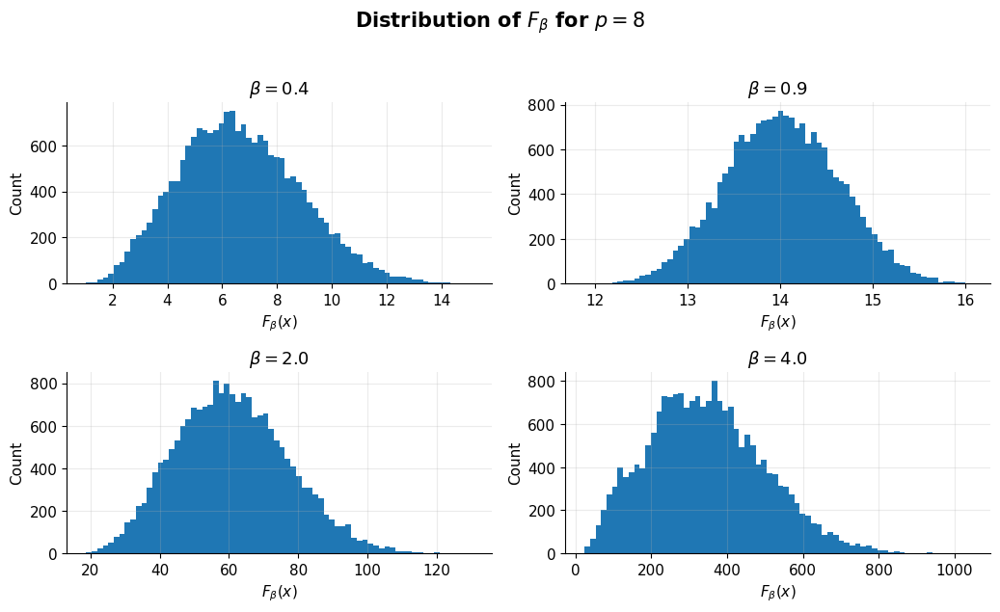

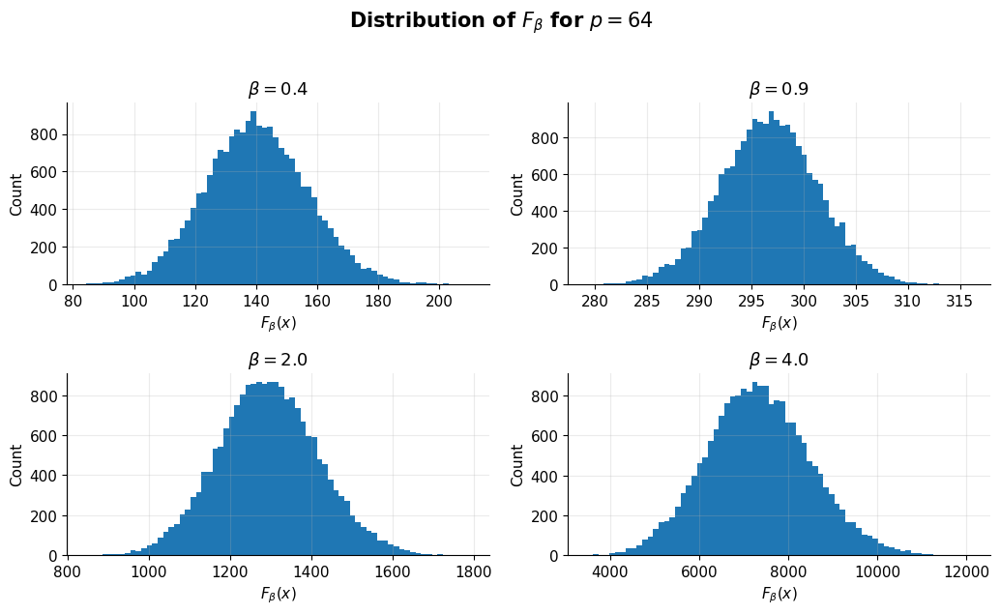

[WindowsPath('generated_article_figures/F_distribution_p8.png'),
 WindowsPath('generated_article_figures/F_distribution_p64.png')]

In [5]:

def make_F_distributions(p, sample_size=20000, betas=(0.4, 0.9, 2.0, 4.0), seed=10):
    local_rng = np.random.default_rng(seed)
    genes = random_genes(sample_size, p, local_rng)
    data = {rf"$\beta={beta}$": F_beta(genes, beta) for beta in betas}
    fig = plot_hist_family(
        data,
        bins=70,
        title=rf"Distribution of $F_\beta$ for $p={p}$",
        xlabel=rf"$F_\beta(x)$",
        ylabel="Count",
        ncols=2,
        figsize=(10.5, 6.2),
    )
    return fig

fig = make_F_distributions(8)
path_F_p8 = save_fig(fig, "F_distribution_p8")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

fig = make_F_distributions(64)
path_F_p64 = save_fig(fig, "F_distribution_p64")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_F_p8, path_F_p64]


## Relative differences of $F_\beta$ by gene distance

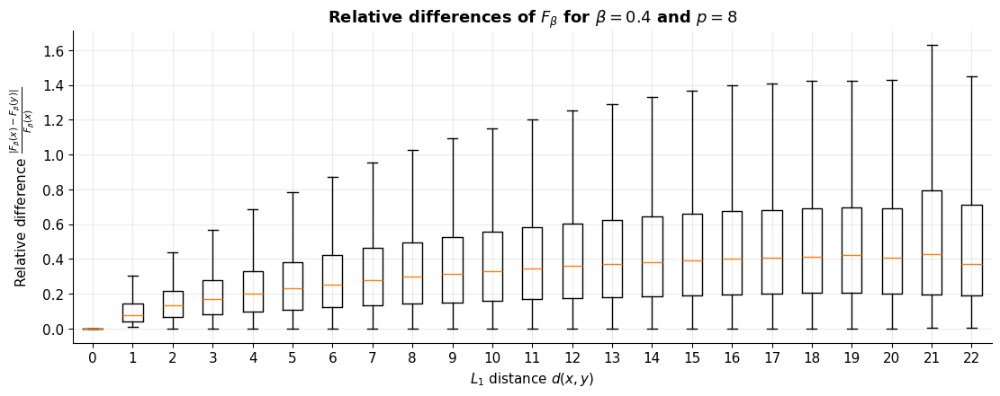

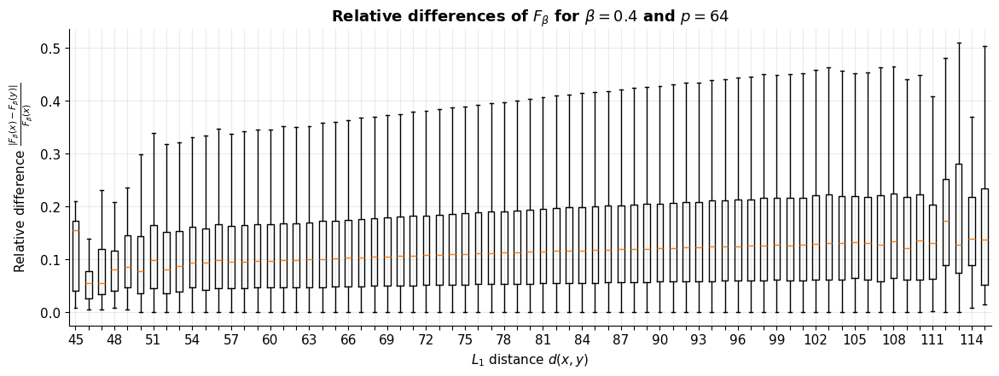

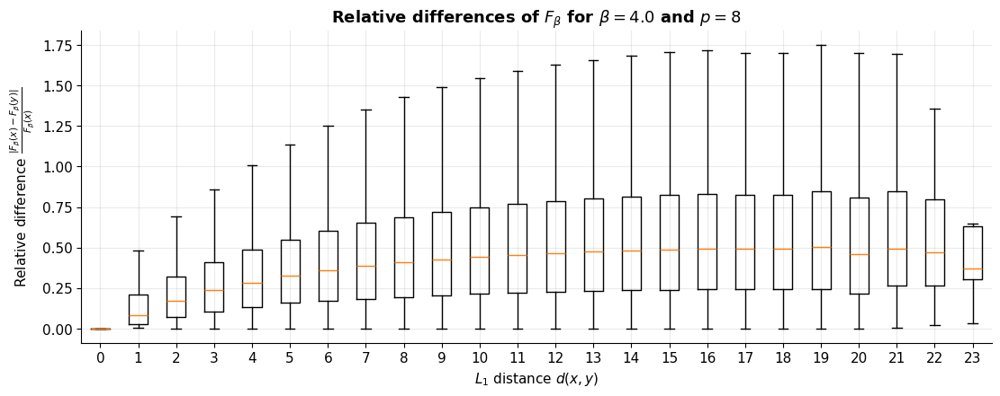

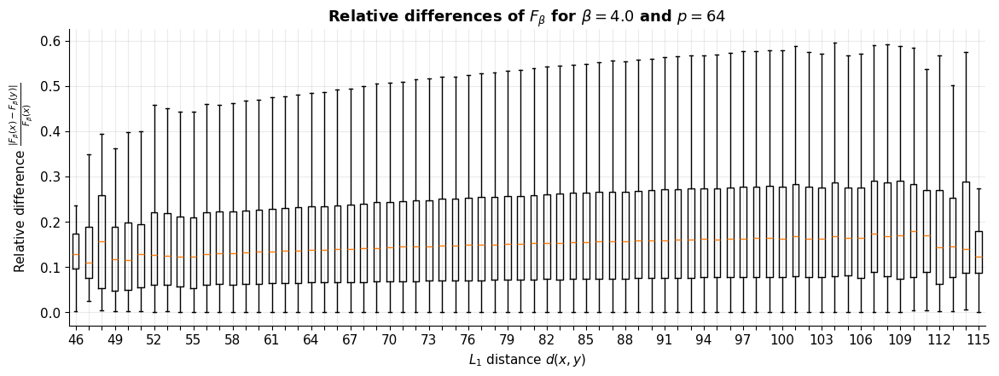

In [6]:
## Relative differences of $F_\beta$ by gene distance

def _boxplot_relative_F(distances, rel_diffs, *, title="", max_distance=None, figsize=(11, 4.3), min_count=12):
    distances = np.asarray(distances)
    rel_diffs = np.asarray(rel_diffs)

    unique = np.unique(distances)
    if max_distance is not None:
        unique = unique[unique <= max_distance]

    tick_labels = []
    series = []

    for d in unique:
        vals = rel_diffs[distances == d]
        if vals.size >= min_count:
            tick_labels.append(int(d))
            series.append(vals)

    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    ax.boxplot(series, tick_labels=tick_labels, showfliers=False)
    ax.set_title(title)
    ax.set_xlabel(r"$L_1$ distance $d(x,y)$")
    ax.set_ylabel(r"Relative difference $\frac{|F_\beta(x)-F_\beta(y)|}{F_\beta(x)}$")

    if len(tick_labels) > 25:
        step = max(1, len(tick_labels) // 18)
        for idx, tick in enumerate(ax.get_xticklabels()):
            tick.set_visible(idx % step == 0)

    return fig


for beta, p, tag in [
    (0.4, 8,  "F_relative_beta04_p8"),
    (0.4, 64, "F_relative_beta04_p64"),
    (4.0, 8,  "F_relative_beta4_p8"),
    (4.0, 64, "F_relative_beta4_p64"),
]:
    d, rel = sample_relative_differences(
        p=p,
        beta=beta,
        num_pairs=10000000,
        seed=int(beta * 100 + p)
    )

    # Full sampled distance range in a single panel for each beta and p.
    fig = _boxplot_relative_F(
        d,
        rel,
        title=rf"Relative differences of $F_\beta$ for $\beta={beta}$ and $p={p}$",
        figsize=(11.6, 4.3) if p == 64 else (11, 4.3),
        min_count=12
    )

    save_fig(fig, tag)
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


## Distributions of $G_{\delta_1,\delta_2}$

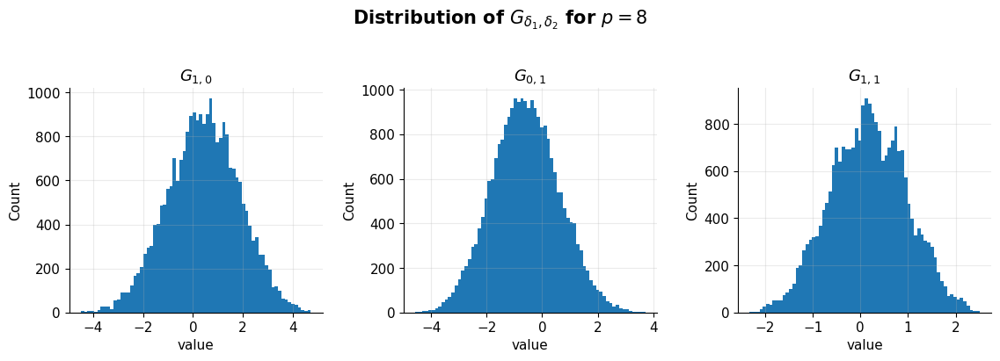

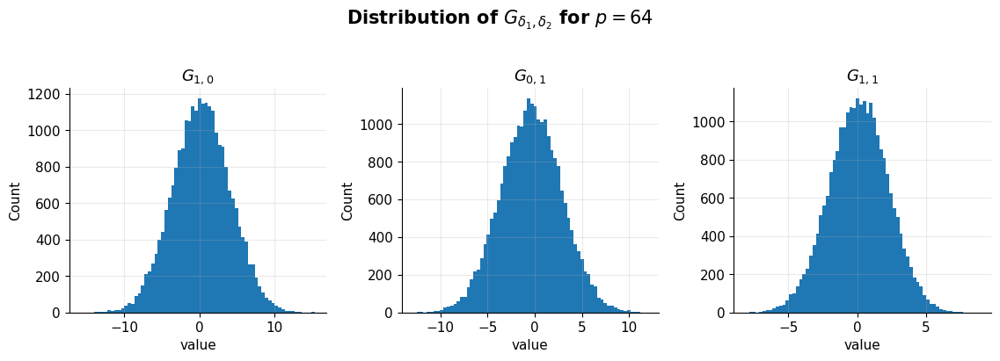

[WindowsPath('generated_article_figures/G_distribution_p8.png'),
 WindowsPath('generated_article_figures/G_distribution_p64.png')]

In [7]:

def make_G_distributions(p, sample_size=25000, seed=30):
    local_rng = np.random.default_rng(seed)
    genes = random_genes(sample_size, p, local_rng)
    combos = [(1, 0), (0, 1), (1, 1)]
    data = {rf"$G_{{{d1},{d2}}}$": G_value(genes, d1, d2) for d1, d2 in combos}
    fig = plot_hist_family(
        data,
        bins=70,
        title=rf"Distribution of $G_{{\delta_1,\delta_2}}$ for $p={p}$",
        xlabel="value",
        ylabel="Count",
        ncols=3,
        figsize=(11.5, 4.0),
    )
    return fig

fig = make_G_distributions(8)
path_G_p8 = save_fig(fig, "G_distribution_p8")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

fig = make_G_distributions(64)
path_G_p64 = save_fig(fig, "G_distribution_p64")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_G_p8, path_G_p64]


## Distributions of $N_{\max}$ and $S(y)$

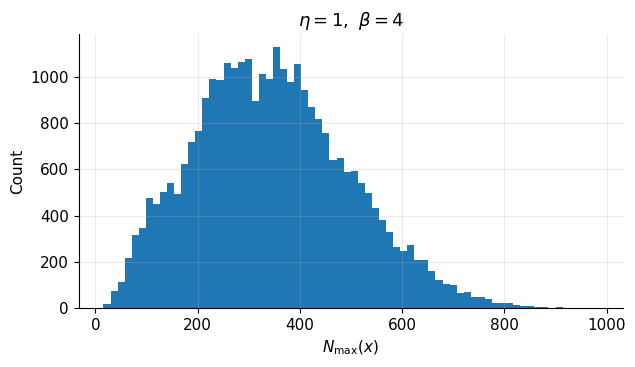

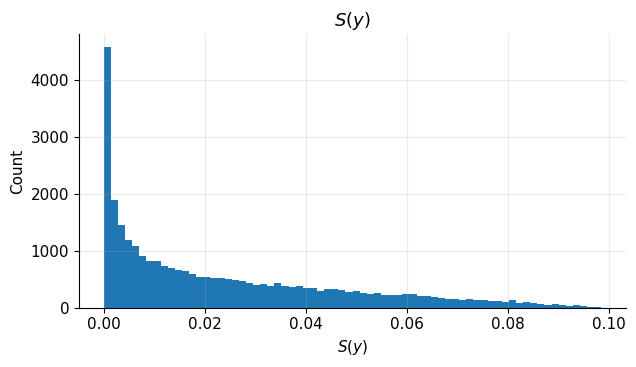

[WindowsPath('generated_article_figures/Nmax_distribution.png'),
 WindowsPath('generated_article_figures/S_distribution.png')]

In [8]:

# Distributions of N_max and S(y)

N_SAMPLES = 30000
N_BINS = 70

# N_max
local_rng = np.random.default_rng(40)
genes = random_genes(N_SAMPLES, 8, local_rng)

nmax_values = np.array([
    Nmax_fixed_beta(g, beta=4.0, eta=1.0)
    for g in genes
])

fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.hist(nmax_values, bins=N_BINS)

ax.set_title(r"$\eta=1,\ \beta=4$")
ax.set_xlabel(r"$N_{\max}(x)$")
ax.set_ylabel("Count")

fig.tight_layout()

path_Nmax = save_fig(fig, "Nmax_distribution")

if SHOW_FIGURES:
    plt.show()
plt.close(fig)


# S(y)
local_rng = np.random.default_rng(41)
genes = random_genes(N_SAMPLES, 64, local_rng)

S_samples = S_value(genes)

fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.hist(S_samples, bins=N_BINS)

ax.set_title(r"$S(y)$")
ax.set_xlabel(r"$S(y)$")
ax.set_ylabel("Count")

fig.tight_layout()

path_S = save_fig(fig, "S_distribution")

if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_Nmax, path_S]


## Connection region and slice-interleaved ordering

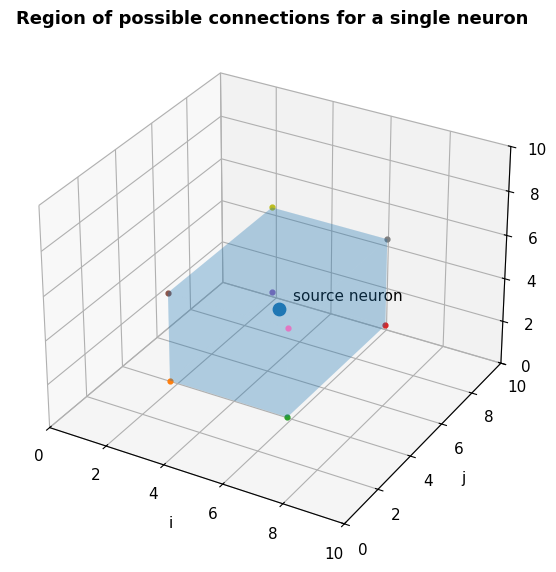

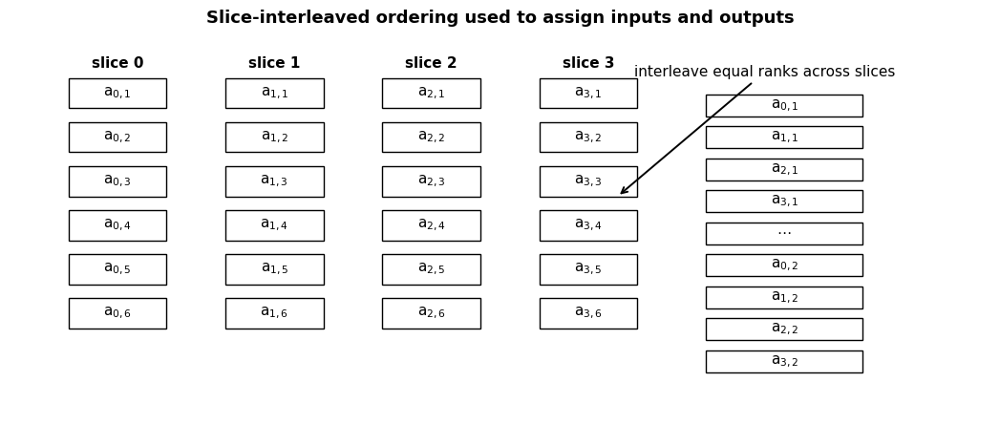

[WindowsPath('generated_article_figures/connection_region.png'),
 WindowsPath('generated_article_figures/ordering_scheme.png')]

In [9]:

# rectangular search region
fig = plt.figure(figsize=(7.7, 5.8))
ax = fig.add_subplot(111, projection='3d')
I = J = K = 10
source = np.array([5, 5, 4])
rx, ry, rz = 2, 3, 2
x0, x1 = source[0] - rx, source[0] + rx
y0, y1 = source[1] - ry, source[1] + ry
z0, z1 = source[2] - rz, source[2] + rz

corners = np.array([
    [x0, y0, z0], [x1, y0, z0], [x1, y1, z0], [x0, y1, z0],
    [x0, y0, z1], [x1, y0, z1], [x1, y1, z1], [x0, y1, z1],
])
faces = [
    [corners[j] for j in [0, 1, 2, 3]],
    [corners[j] for j in [4, 5, 6, 7]],
    [corners[j] for j in [0, 1, 5, 4]],
    [corners[j] for j in [2, 3, 7, 6]],
    [corners[j] for j in [1, 2, 6, 5]],
    [corners[j] for j in [0, 3, 7, 4]],
]
poly = Poly3DCollection(faces, alpha=0.18)
ax.add_collection3d(poly)
ax.scatter(*source, s=80)
for pt in corners:
    ax.scatter(*pt, s=12)
ax.text(*(source + np.array([0.3, 0.3, 0.3])), "source neuron")
ax.set_xlim(0, I)
ax.set_ylim(0, J)
ax.set_zlim(0, K)
ax.set_xlabel('i')
ax.set_ylabel('j')
ax.set_zlabel('k')
ax.set_title("Region of possible connections for a single neuron")
fig.tight_layout()
path_connection_region = save_fig(fig, "connection_region")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# ordering scheme
fig, ax = plt.subplots(figsize=(10.6, 4.8))
ax.axis('off')
num_slices = 4
ranks = 6
slice_xs = [0.06, 0.22, 0.38, 0.54]
for s, x in enumerate(slice_xs):
    ax.text(x + 0.05, 0.92, f"slice {s}", transform=ax.transAxes, ha='center', weight='bold')
    for r in range(ranks):
        y = 0.82 - r * 0.11
        rect = patches.Rectangle((x, y), 0.1, 0.075, fill=False, transform=ax.transAxes)
        ax.add_patch(rect)
        ax.text(x + 0.05, y + 0.037, f"a$_{{{s},{r+1}}}$", transform=ax.transAxes, ha='center', va='center')

ax.annotate("interleave equal ranks across slices", xy=(0.62, 0.6), xytext=(0.77, 0.9),
            xycoords=ax.transAxes, textcoords=ax.transAxes,
            arrowprops=dict(arrowstyle='->', lw=1.4), ha='center')

seq_x = 0.71
for idx, label in enumerate([f"a$_{{{s},1}}$" for s in range(num_slices)] + ["⋯"] + [f"a$_{{{s},2}}$" for s in range(num_slices)]):
    y = 0.8 - idx * 0.08
    rect = patches.Rectangle((seq_x, y), 0.16, 0.055, fill=False, transform=ax.transAxes)
    ax.add_patch(rect)
    ax.text(seq_x + 0.08, y + 0.027, label, transform=ax.transAxes, ha='center', va='center')

ax.set_title("Slice-interleaved ordering used to assign inputs and outputs", pad=10)
fig.tight_layout()
path_ordering_scheme = save_fig(fig, "ordering_scheme")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_connection_region, path_ordering_scheme]


## Saturation and threshold distribution

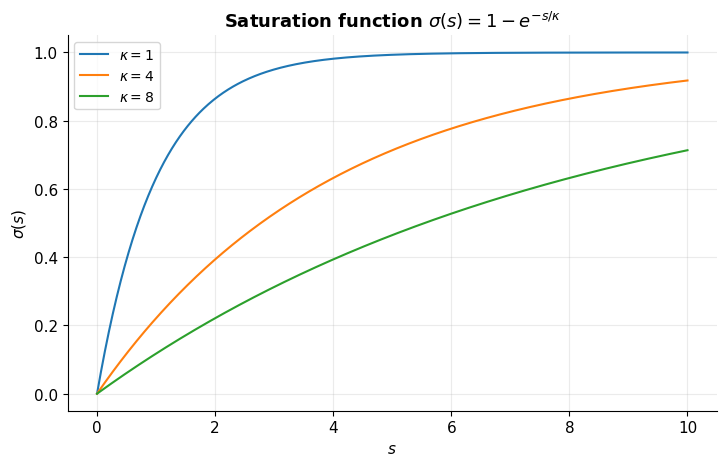

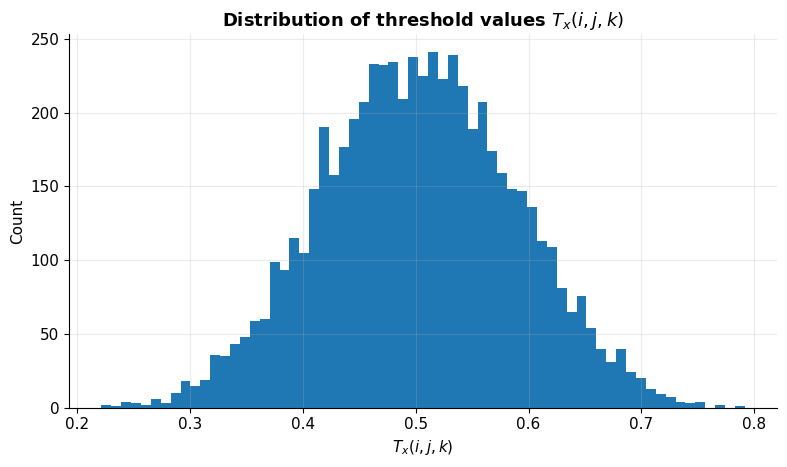

[WindowsPath('generated_article_figures/saturation_function.png'),
 WindowsPath('generated_article_figures/threshold_distribution.png')]

In [10]:

# saturation function
s = np.linspace(0, 10, 600)
fig, ax = plt.subplots(figsize=(7.4, 4.8))
for kappa in [1, 4, 8]:
    ax.plot(s, sigma(s, kappa), label=rf"$\kappa={kappa}$")
ax.set_title(r"Saturation function $\sigma(s)=1-e^{-s/\kappa}$")
ax.set_xlabel(r"$s$")
ax.set_ylabel(r"$\sigma(s)$")
ax.legend()
fig.tight_layout()
path_saturation = save_fig(fig, "saturation_function")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# threshold distribution at a fixed neuron, random genes
fixed_pos = (7, 7, 3)
dims = (50, 50, 10)
local_rng = np.random.default_rng(50)
threshold_samples = []
for gene in random_genes(6000, 64, local_rng):
    A = A_volume(gene, dims)
    threshold_samples.append(threshold_from_A(A[fixed_pos]))
threshold_samples = np.array(threshold_samples)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(threshold_samples, bins=65)
ax.set_title(r"Distribution of threshold values $T_x(i,j,k)$")
ax.set_xlabel(r"$T_x(i,j,k)$")
ax.set_ylabel("Count")
fig.tight_layout()
path_threshold = save_fig(fig, "threshold_distribution")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_saturation, path_threshold]


## Neighborhood, decay, retention, plasticity, and input influence

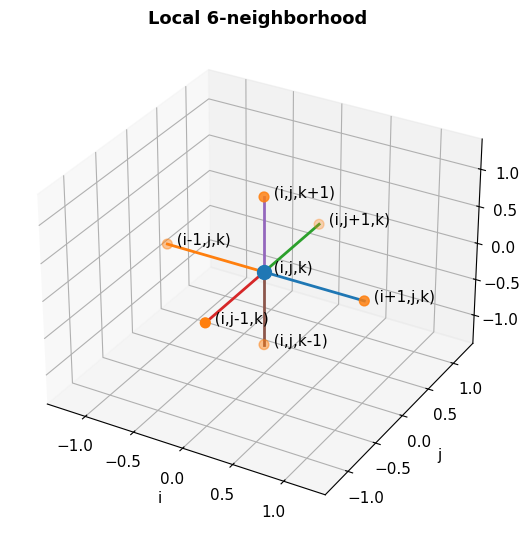

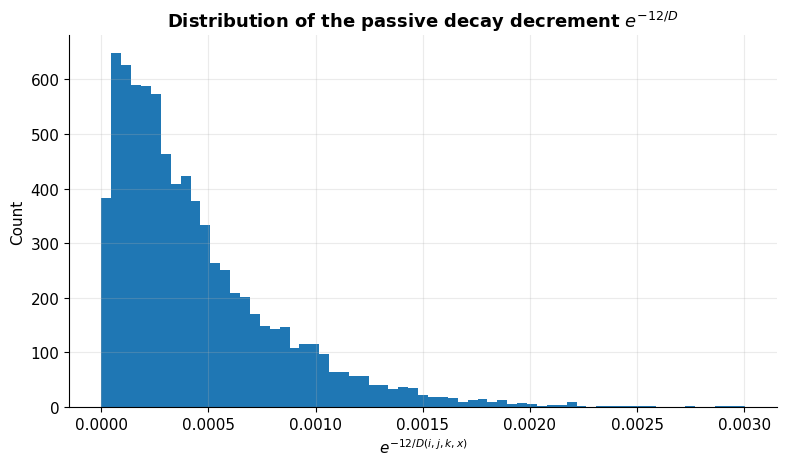

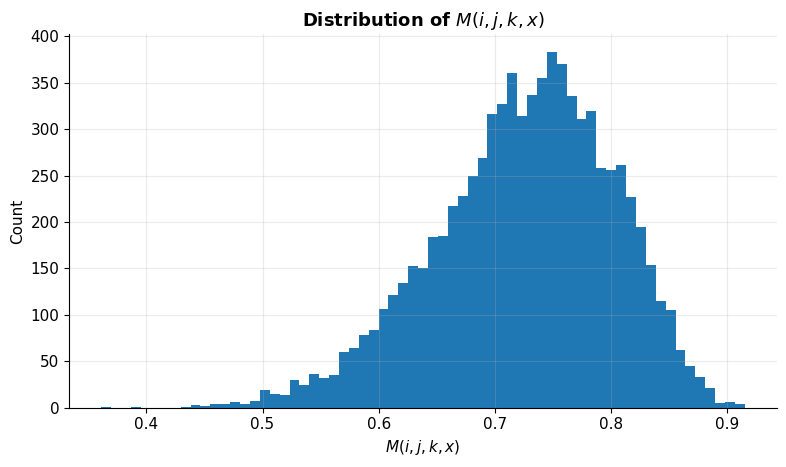

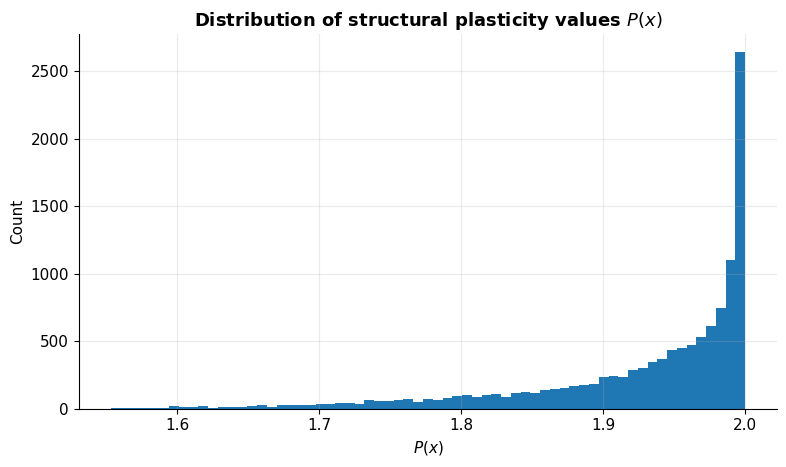

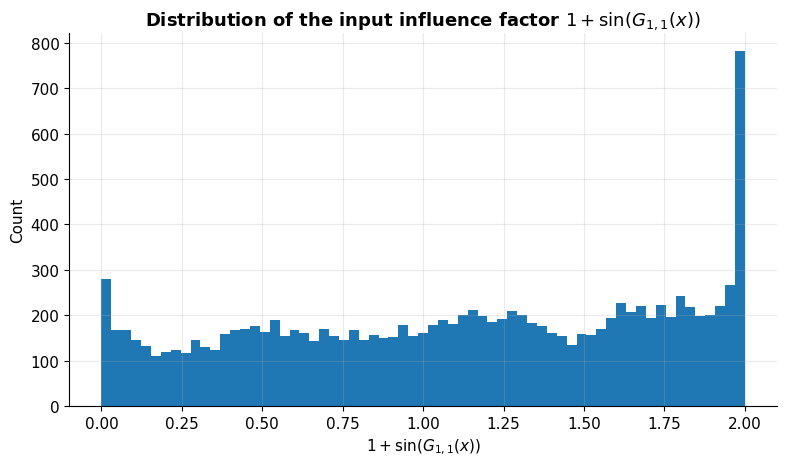

[WindowsPath('generated_article_figures/local_neighborhood.png'),
 WindowsPath('generated_article_figures/decay_distribution.png'),
 WindowsPath('generated_article_figures/retention_distribution.png'),
 WindowsPath('generated_article_figures/plasticity_distribution.png'),
 WindowsPath('generated_article_figures/input_influence_distribution.png')]

In [11]:

# local 6-neighborhood
fig = plt.figure(figsize=(7.0, 5.5))
ax = fig.add_subplot(111, projection='3d')
center = np.array([0, 0, 0])
neighbors = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]])
for nb in neighbors:
    ax.plot([0, nb[0]], [0, nb[1]], [0, nb[2]], lw=2)
ax.scatter([0], [0], [0], s=100)
ax.scatter(neighbors[:,0], neighbors[:,1], neighbors[:,2], s=50)
labels = ["(i+1,j,k)", "(i-1,j,k)", "(i,j+1,k)", "(i,j-1,k)", "(i,j,k+1)", "(i,j,k-1)"]
for pt, lab in zip(neighbors, labels):
    ax.text(pt[0], pt[1], pt[2], "  " + lab)
ax.text(0, 0, 0, "  (i,j,k)")
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.set_zlim(-1.4, 1.4)
ax.set_title("Local 6-neighborhood")
ax.set_xlabel('i')
ax.set_ylabel('j')
ax.set_zlabel('k')
fig.tight_layout()
path_neighborhood = save_fig(fig, "local_neighborhood")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# Shared random genes for parameter distributions
local_rng = np.random.default_rng(60)
genes64 = random_genes(8000, 64, local_rng)
genes8 = random_genes(12000, 8, local_rng)
fixed_pos = (7, 7, 3)
dims = (50, 50, 10)
A_samples = np.array([A_volume(g, dims)[fixed_pos] for g in genes64])

# decay distribution
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(decay_factor_from_A(A_samples), bins=65)
ax.set_title(r"Distribution of the passive decay decrement $e^{-12/D}$")
ax.set_xlabel(r"$e^{-12/D(i,j,k,x)}$")
ax.set_ylabel("Count")
fig.tight_layout()
path_decay = save_fig(fig, "decay_distribution")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# M distribution
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(retention_from_A(A_samples), bins=65)
ax.set_title(r"Distribution of $M(i,j,k,x)$")
ax.set_xlabel(r"$M(i,j,k,x)$")
ax.set_ylabel("Count")
fig.tight_layout()
path_retention = save_fig(fig, "retention_distribution")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# structural plasticity threshold
P_vals = np.array([plasticity_threshold(g) for g in genes8])
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(P_vals, bins=65)
ax.set_title(r"Distribution of structural plasticity values $P(x)$")
ax.set_xlabel(r"$P(x)$")
ax.set_ylabel("Count")
fig.tight_layout()
path_plasticity = save_fig(fig, "plasticity_distribution")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# input influence factor
phi_vals = np.array([input_influence_factor(g) for g in genes8])
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(phi_vals, bins=65)
ax.set_title(r"Distribution of the input influence factor $1+\sin(G_{1,1}(x))$")
ax.set_xlabel(r"$1+\sin(G_{1,1}(x))$")
ax.set_ylabel("Count")
fig.tight_layout()
path_input_influence = save_fig(fig, "input_influence_distribution")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_neighborhood, path_decay, path_retention, path_plasticity, path_input_influence]


## Temporal order of the operations affecting existing connections

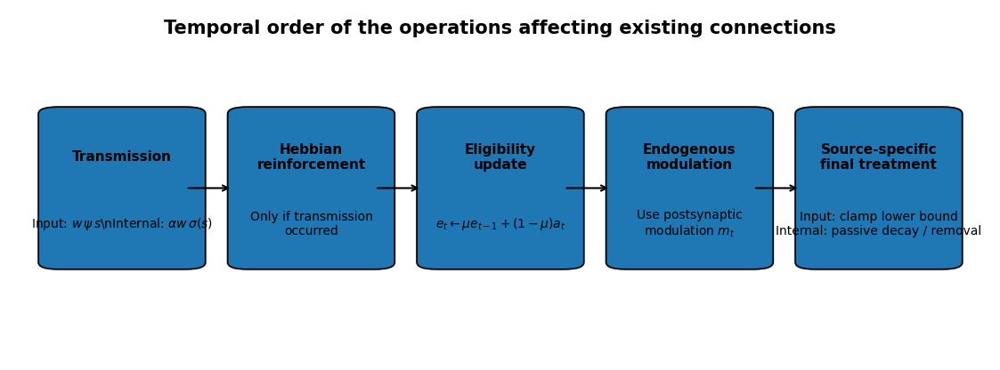

WindowsPath('generated_article_figures/connection_timeline.png')

In [12]:
fig, ax = plt.subplots(figsize=(11.5, 4.3))
ax.axis('off')
steps = [
    "Transmission",
    "Hebbian\nreinforcement",
    "Eligibility\nupdate",
    "Endogenous\nmodulation",
    "Source-specific\nfinal treatment",
]
subtext = [
    r"Input: $w\,\psi\,s$\nInternal: $\alpha w\,\sigma(s)$",
    "Only if transmission\noccurred",
    r"$e_t \leftarrow \mu e_{t-1} + (1-\mu)a_t$",
    "Use postsynaptic\nmodulation $m_t$",
    "Input: clamp lower bound\nInternal: passive decay / removal",
]
xs = np.linspace(0.05, 0.82, len(steps))
for x, title, body in zip(xs, steps, subtext):
    box = patches.FancyBboxPatch((x, 0.28), 0.13, 0.42, boxstyle="round,pad=0.02", transform=ax.transAxes, linewidth=1.3)
    ax.add_patch(box)
    ax.text(x + 0.065, 0.58, title, transform=ax.transAxes, ha='center', va='center', weight='bold')
    ax.text(x + 0.065, 0.39, body, transform=ax.transAxes, ha='center', va='center', fontsize=10)
for i in range(len(xs) - 1):
    ax.annotate("", xy=(xs[i+1] - 0.015, 0.49), xytext=(xs[i] + 0.13, 0.49), xycoords=ax.transAxes,
                arrowprops=dict(arrowstyle='->', lw=1.5))
ax.text(0.5, 0.93, "Temporal order of the operations affecting existing connections",
        transform=ax.transAxes, ha='center', fontsize=15, fontweight='bold')
fig.tight_layout()
path_connection_timeline = save_fig(fig, "connection_timeline")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_connection_timeline

## Conceptual organization of the complete brain and its data on the GPU

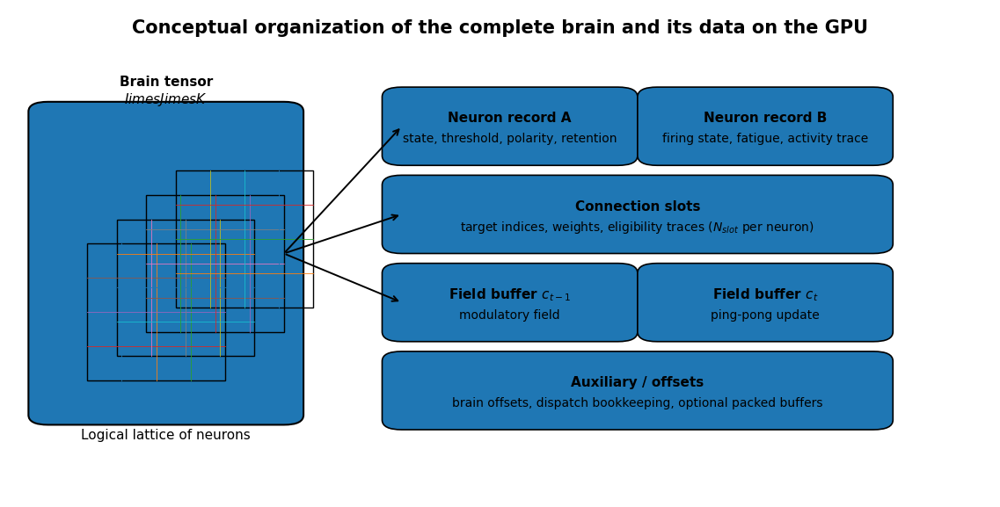

WindowsPath('generated_article_figures/gpu_organization.png')

In [13]:
fig, ax = plt.subplots(figsize=(11.5, 5.9))
ax.axis('off')

# Left: brain tensor
brain_box = patches.FancyBboxPatch((0.04, 0.17), 0.24, 0.62, boxstyle="round,pad=0.02", linewidth=1.5, transform=ax.transAxes)
ax.add_patch(brain_box)
for idx in range(4):
    x = 0.08 + idx * 0.03
    y = 0.24 + idx * 0.05
    rect = patches.Rectangle((x, y), 0.14, 0.28, fill=False, transform=ax.transAxes, linewidth=1.0)
    ax.add_patch(rect)
    for gx in np.linspace(x + 0.14/4, x + 3*0.14/4, 3):
        ax.plot([gx, gx], [y, y + 0.28], transform=ax.transAxes, lw=0.6)
    for gy in np.linspace(y + 0.28/4, y + 3*0.28/4, 3):
        ax.plot([x, x + 0.14], [gy, gy], transform=ax.transAxes, lw=0.6)
ax.text(0.16, 0.83, "Brain tensor\n$I \times J \times K$", transform=ax.transAxes, ha='center', va='center', weight='bold')
ax.text(0.16, 0.12, "Logical lattice of neurons", transform=ax.transAxes, ha='center')

# Right: data blocks
blocks = [
    (0.40, 0.70, 0.22, 0.12, "Neuron record A", "state, threshold, polarity, retention"),
    (0.66, 0.70, 0.22, 0.12, "Neuron record B", "firing state, fatigue, activity trace"),
    (0.40, 0.52, 0.48, 0.12, "Connection slots", r"target indices, weights, eligibility traces ($N_{slot}$ per neuron)"),
    (0.40, 0.34, 0.22, 0.12, "Field buffer $c_{t-1}$", "modulatory field"),
    (0.66, 0.34, 0.22, 0.12, "Field buffer $c_t$", "ping-pong update"),
    (0.40, 0.16, 0.48, 0.12, "Auxiliary / offsets", "brain offsets, dispatch bookkeeping, optional packed buffers"),
]
for x, y, w, h, title, desc in blocks:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", linewidth=1.2, transform=ax.transAxes)
    ax.add_patch(box)
    ax.text(x + w/2, y + h*0.63, title, transform=ax.transAxes, ha='center', va='center', weight='bold')
    ax.text(x + w/2, y + h*0.28, desc, transform=ax.transAxes, ha='center', va='center', fontsize=10)

for y in [0.76, 0.58, 0.40]:
    ax.annotate("", xy=(0.40, y), xytext=(0.28, 0.50), xycoords=ax.transAxes,
                arrowprops=dict(arrowstyle='->', lw=1.4))

ax.text(0.5, 0.95, "Conceptual organization of the complete brain and its data on the GPU",
        transform=ax.transAxes, ha='center', fontsize=15, fontweight='bold')
fig.tight_layout()
path_gpu_organization = save_fig(fig, "gpu_organization")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_gpu_organization

## Schematic view of the neuronal dynamics

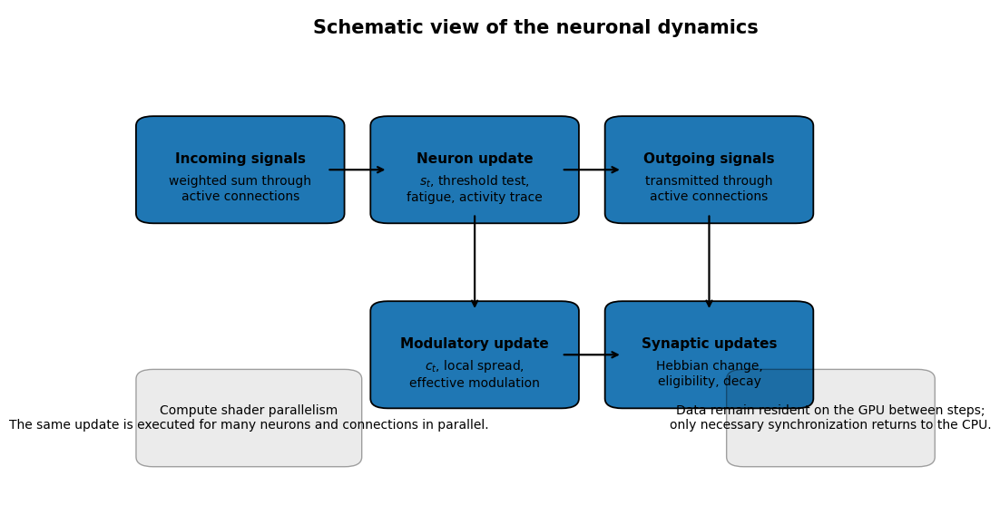

WindowsPath('generated_article_figures/neuronal_dynamics_schematic.png')

In [14]:
fig, ax = plt.subplots(figsize=(11.4, 5.7))
ax.axis('off')

boxes = [
    (0.06, 0.58, 0.2, 0.18, "Incoming signals", "weighted sum through\nactive connections"),
    (0.33, 0.58, 0.2, 0.18, "Neuron update", "$s_t$, threshold test,\nfatigue, activity trace"),
    (0.60, 0.58, 0.2, 0.18, "Outgoing signals", "transmitted through\nactive connections"),
    (0.33, 0.20, 0.2, 0.18, "Modulatory update", "$c_t$, local spread,\neffective modulation"),
    (0.60, 0.20, 0.2, 0.18, "Synaptic updates", "Hebbian change,\neligibility, decay"),
]
for x, y, w, h, title, body in boxes:
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", linewidth=1.3, transform=ax.transAxes)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h*0.62, title, transform=ax.transAxes, ha='center', va='center', weight='bold')
    ax.text(x + w/2, y + h*0.28, body, transform=ax.transAxes, ha='center', va='center', fontsize=10)

arrows = [((0.26, 0.67), (0.33, 0.67)), ((0.53, 0.67), (0.60, 0.67)), ((0.43, 0.58), (0.43, 0.38)), ((0.53, 0.29), (0.60, 0.29)), ((0.70, 0.58), (0.70, 0.38))]
for a, b in arrows:
    ax.annotate("", xy=b, xytext=a, xycoords=ax.transAxes, arrowprops=dict(arrowstyle='->', lw=1.6))

annotate_panel(ax, "Compute shader parallelism\nThe same update is executed for many neurons and connections in parallel.", (0.06, 0.08), 0.22, 0.16, fontsize=10)
annotate_panel(ax, "Data remain resident on the GPU between steps;\nonly necessary synchronization returns to the CPU.", (0.74, 0.08), 0.20, 0.16, fontsize=10)
ax.text(0.5, 0.95, "Schematic view of the neuronal dynamics",
        transform=ax.transAxes, ha='center', fontsize=15, fontweight='bold')
fig.tight_layout()
path_neuronal_dynamics = save_fig(fig, "neuronal_dynamics_schematic")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_neuronal_dynamics

In [15]:
# Helpers for comparing different spatial genes on a SINGLE fixed slice.

def mutate_exact_positions(base_gene, count, generator):
    """Change exactly `count` digit positions to different values (0..3)."""
    result = np.asarray(base_gene, dtype=np.int64).copy()
    if not (0 <= count <= result.size):
        raise ValueError("count must be in 0..p")
    if count:
        ids = generator.choice(result.size, size=count, replace=False)
        offsets = generator.integers(1, 4, size=count)
        result[ids] = (result[ids] + offsets) % 4
    assert np.count_nonzero(result != base_gene) == count
    return result


def plot_gene_comparison(volumes, labels, k, title, *, cmap="coolwarm", source=None, zero_contour=False):
    """Each input is a different full 3D field; same fixed slice and [-1,1] color limits."""
    if len(volumes) != len(labels) or not (1 <= len(volumes) <= 6):
        raise ValueError("Supply 1–6 equal-length panels and titles")
    dims = np.asarray(volumes[0]).shape
    if len(dims) != 3 or not (0 <= k < dims[2]):
        raise ValueError("Invalid 3D volume or slice index")
    if any(np.asarray(v).shape != dims for v in volumes):
        raise ValueError("All volumes must have identical dimensions")

    fig, axes = plt.subplots(2, 3, figsize=(9.6, 6.1), constrained_layout=True)
    axes = axes.ravel()
    im = None
    for idx, (volume, label) in enumerate(zip(volumes, labels)):
        ax = axes[idx]
        panel = np.asarray(volume[:, :, k].T, dtype=float).copy()
        if source is not None and source[2] == k:
            # A source cannot connect to itself: hide that candidate in H maps.
            panel[source[1], source[0]] = np.nan
        im = ax.imshow(panel, origin="lower", interpolation="nearest",
                       cmap=cmap, vmin=-1, vmax=1, aspect="equal")
        ax.grid(False)
        ax.set_title(label, fontsize=11)
        ax.set_xticks([0, dims[0] // 2, dims[0] - 1])
        ax.set_yticks([0, dims[1] // 2, dims[1] - 1])
        ax.set_xlabel("i")
        ax.set_ylabel("j")
        if zero_contour and np.nanmin(panel) < 0 < np.nanmax(panel):
            ax.contour(panel, levels=[0], colors="black", linewidths=0.65, alpha=0.75)
        if source is not None and source[2] == k:
            ax.scatter([source[0]], [source[1]], marker="x", c="black", s=36, linewidths=1.4, zorder=4)

    for ax in axes[len(volumes):]:
        ax.axis("off")

    fig.colorbar(im, ax=axes.tolist(), orientation="horizontal", fraction=0.055,
                 pad=0.065, shrink=0.68, aspect=36, label="Field value (shared scale)")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    return fig


## Extra visualizations -Gene-specific parameter fields

Each parameter below is generated from its **own independent 64-digit gene**. The connection-energy field $A$ is generated with the connections gene; its same gene is used again when computing the connection affinity $H$. All Brain Explorer-style maps refer to the **same brain geometry** but not to the same gene.

In [16]:
# One complete example: independent 64-digit genes for distinct parameters.
# Connection affinity H and the connection energy A MUST share the connection gene.
example_dims = (170, 170, 16)
example_rng = np.random.default_rng(101)

spatial_genes = {
    name: example_rng.integers(0, 4, size=64, dtype=np.int64)
    for name in (
        "connections", "threshold", "retention", "modulatory_release",
        "modulatory_sensitivity", "polarity", "decay"
    )
}
assert len({tuple(g) for g in spatial_genes.values()}) == len(spatial_genes)

# Each mathematical A is evaluated with the gene governing its own parameter.
A_fields = {name: A_volume(g, example_dims) for name, g in spatial_genes.items()}

A_x = A_fields["connections"]  # Connection energy field, for H and the A heatmaps
T_x = threshold_from_A(A_fields["threshold"])
M_x = retention_from_A(A_fields["retention"])
Q_x = Q_from_A(A_fields["modulatory_release"])
R_y = R_from_A(A_fields["modulatory_sensitivity"])
pol_x = polarity_from_A(A_fields["polarity"])
decay_x = decay_factor_from_A(A_fields["decay"])

print("Example brain dimensions:", example_dims)
print("Independent spatial genes:", ", ".join(spatial_genes))
print("Connection A range:", float(A_x.min()), float(A_x.max()))


Example brain dimensions: (170, 170, 16)
Independent spatial genes: connections, threshold, retention, modulatory_release, modulatory_sensitivity, polarity, decay
Connection A range: -0.880635674869813 0.8962699788326111


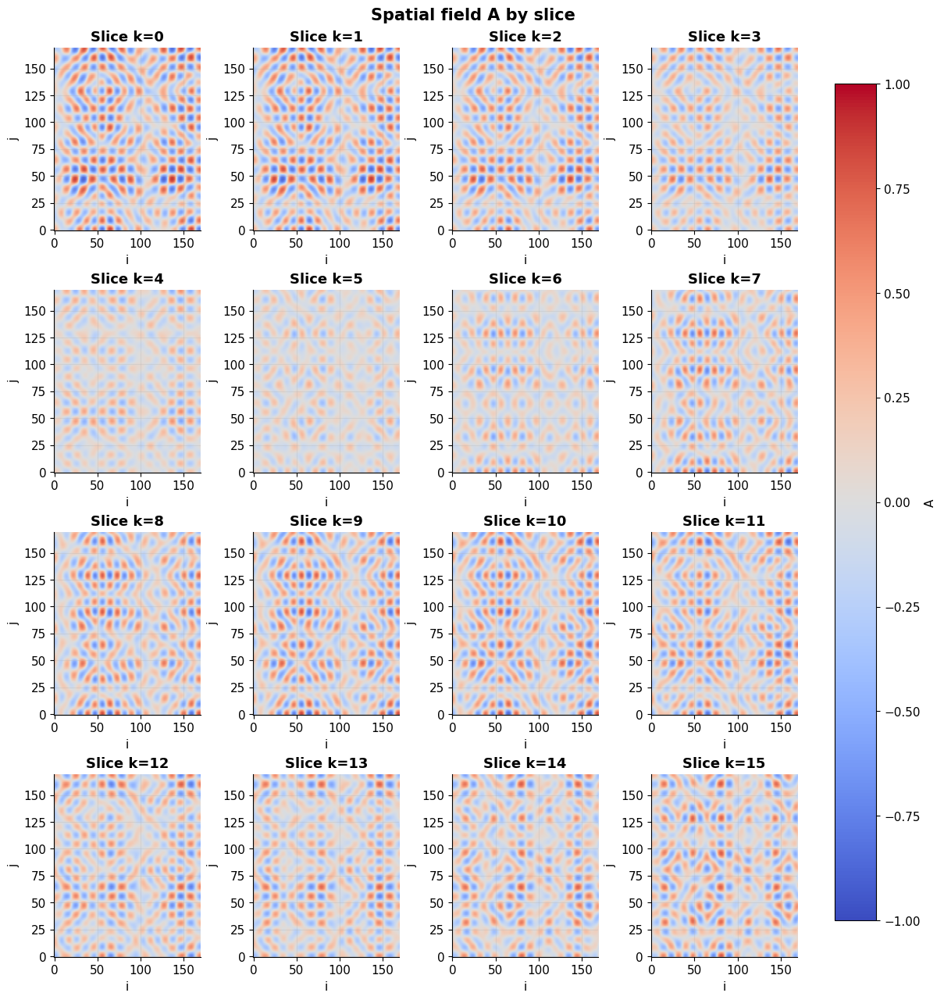

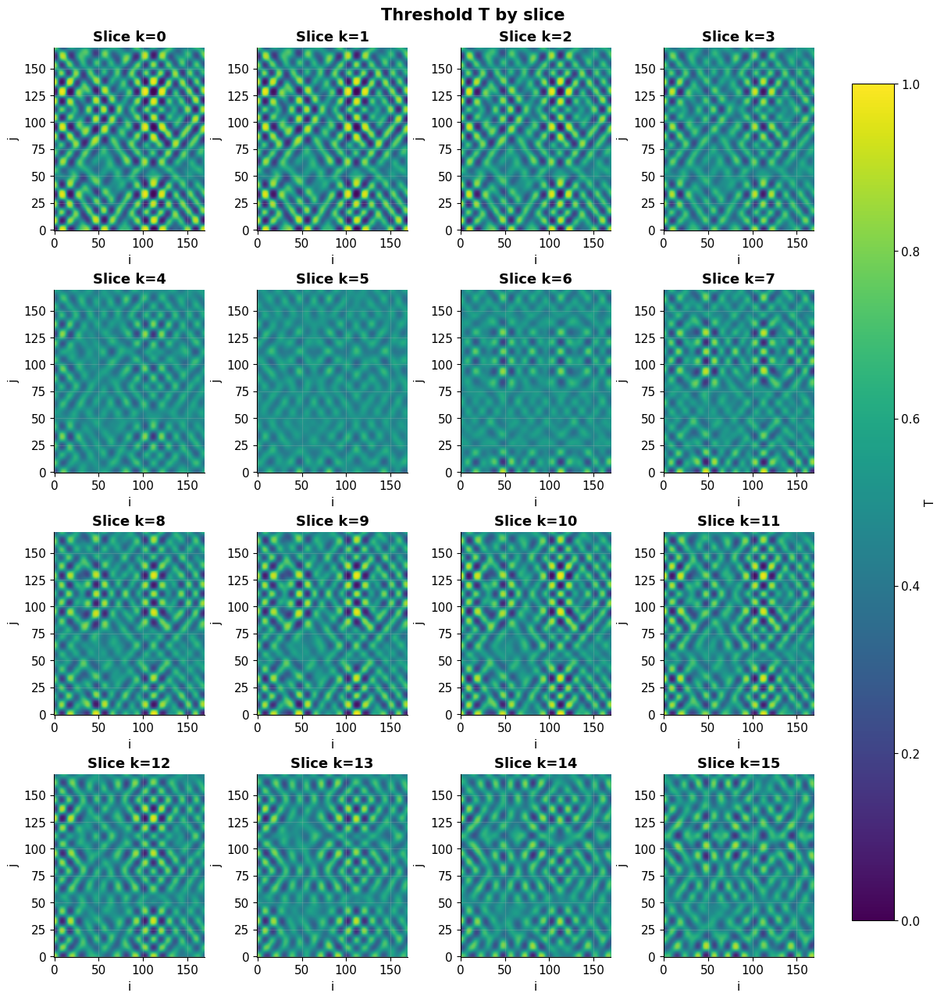

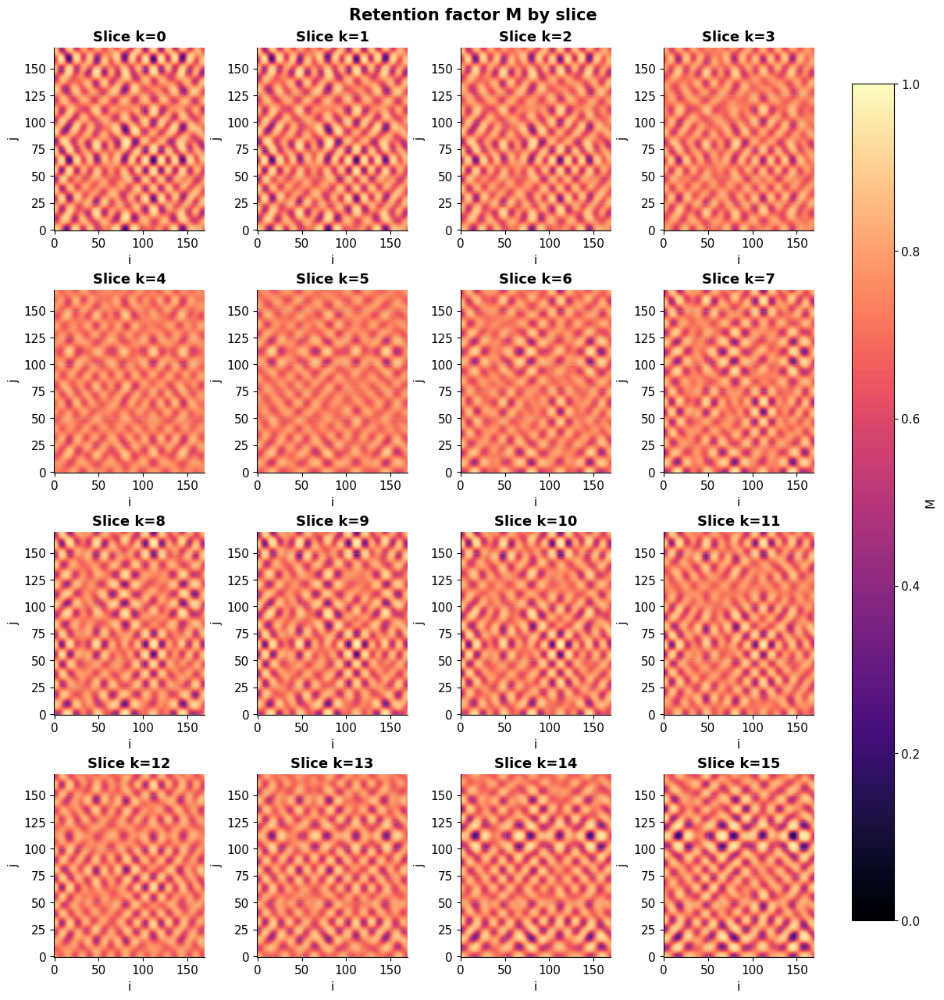

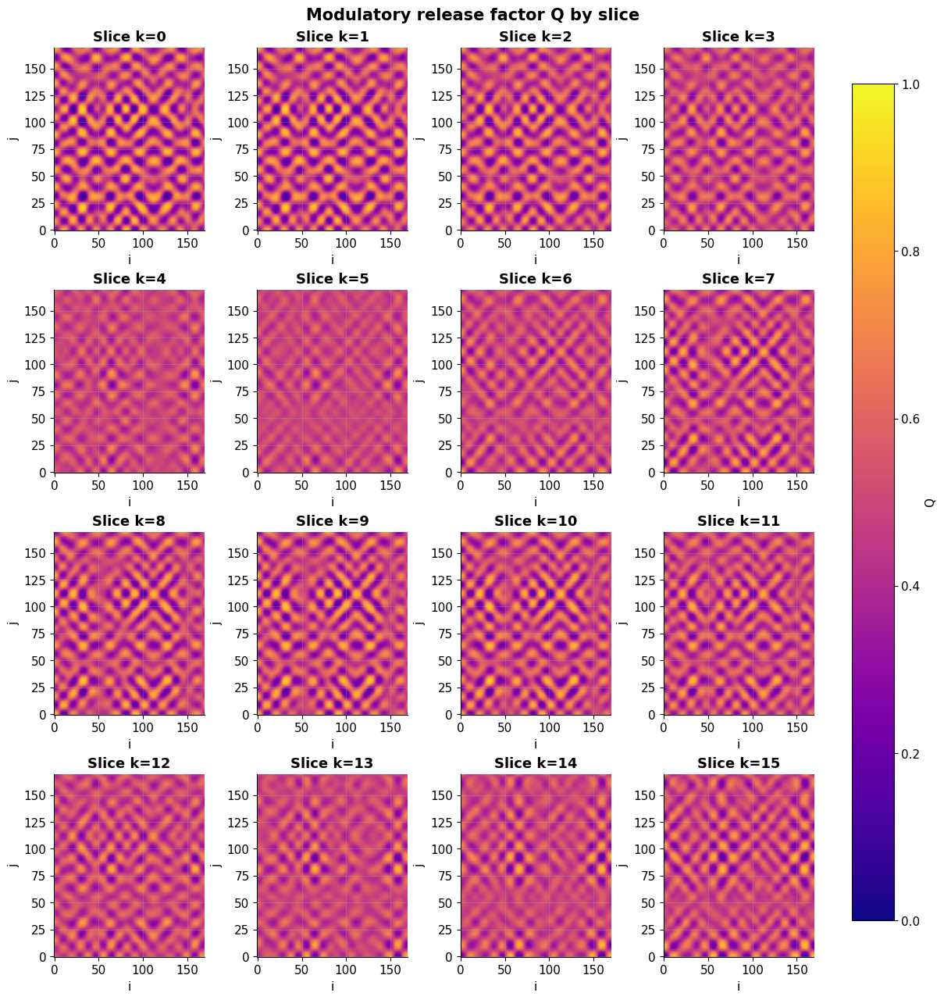

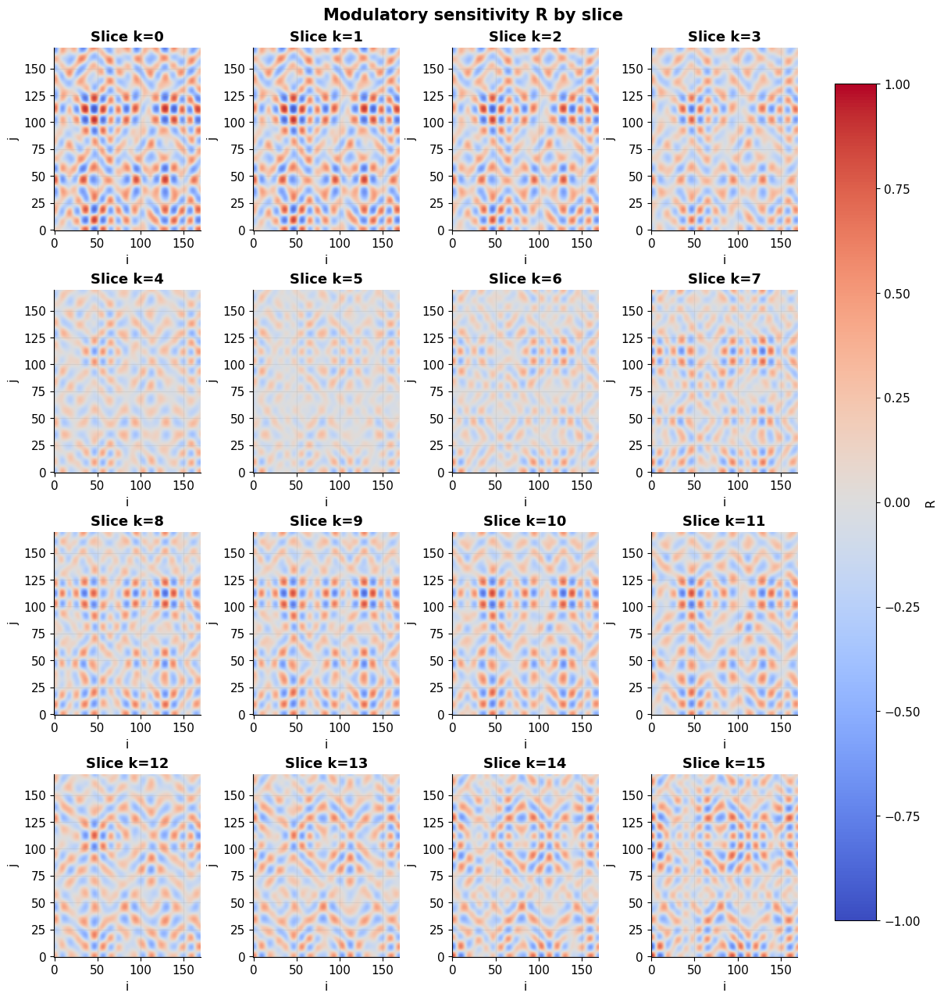

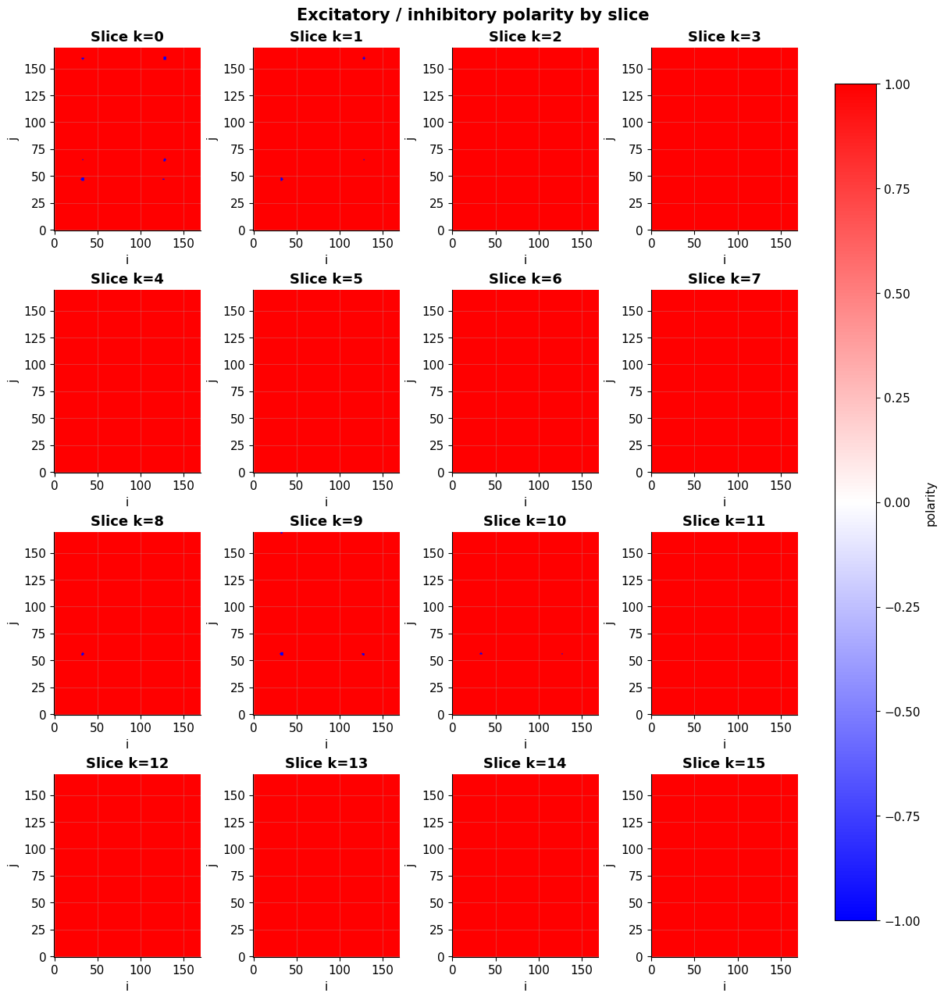

[WindowsPath('generated_article_figures/extra_A_heatmaps.png'),
 WindowsPath('generated_article_figures/extra_threshold_heatmaps.png'),
 WindowsPath('generated_article_figures/extra_retention_heatmaps.png'),
 WindowsPath('generated_article_figures/extra_Q_heatmaps.png'),
 WindowsPath('generated_article_figures/extra_R_heatmaps.png'),
 WindowsPath('generated_article_figures/extra_polarity_heatmaps.png')]

In [17]:

# Heatmap grid of A
fig = heatmap_grid(A_x, title="Spatial field A by slice", cmap="coolwarm", colorbar_label="A", vmin=-1, vmax=1)
path_A = save_fig(fig, "extra_A_heatmaps")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# Heatmap grid of threshold T
fig = heatmap_grid(T_x, title="Threshold T by slice", cmap="viridis", colorbar_label="T", vmin=0, vmax=1)
path_T = save_fig(fig, "extra_threshold_heatmaps")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# Heatmap grid of retention M
fig = heatmap_grid(M_x, title="Retention factor M by slice", cmap="magma", colorbar_label="M", vmin=0, vmax=1)
path_M = save_fig(fig, "extra_retention_heatmaps")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# Heatmap grid of modulatory release Q
fig = heatmap_grid(Q_x, title="Modulatory release factor Q by slice", cmap="plasma", colorbar_label="Q", vmin=0, vmax=1)
path_Q = save_fig(fig, "extra_Q_heatmaps")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# Heatmap grid of modulatory sensitivity R
fig = heatmap_grid(R_y, title="Modulatory sensitivity R by slice", cmap="coolwarm", colorbar_label="R", vmin=-1, vmax=1)
path_R = save_fig(fig, "extra_R_heatmaps")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# Heatmap grid of polarity
fig = heatmap_grid(pol_x.astype(float), title="Excitatory / inhibitory polarity by slice", cmap="bwr", colorbar_label="polarity", vmin=-1, vmax=1)
path_Pol = save_fig(fig, "extra_polarity_heatmaps")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_A, path_T, path_M, path_Q, path_R, path_Pol]


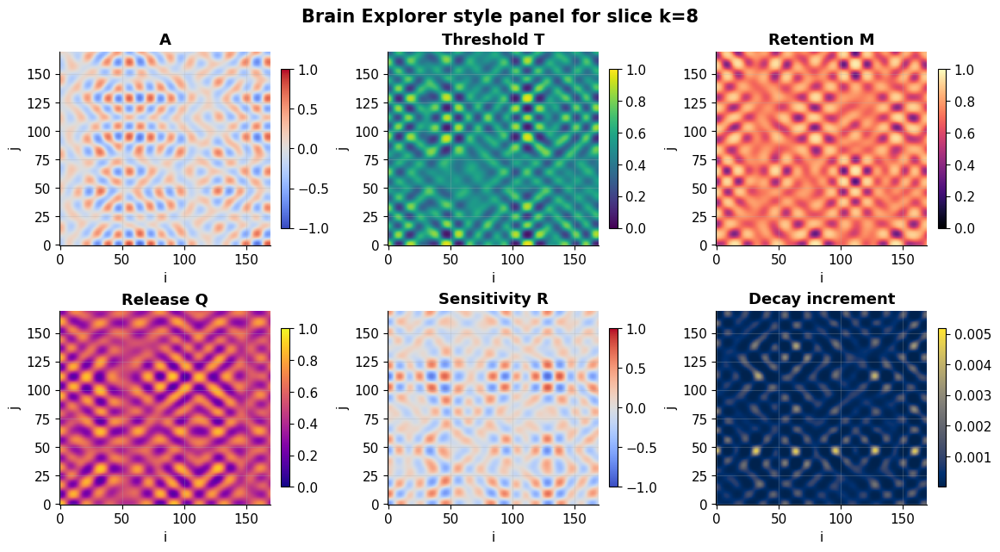

WindowsPath('generated_article_figures/extra_brain_explorer_panel.png')

In [18]:

# Brain Explorer–style side-by-side slice panels for selected quantities on one slice
slice_k = example_dims[2] // 2
fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.3), constrained_layout=True)
panels = [
    (A_x[:, :, slice_k].T, "A", "coolwarm", -1, 1),
    (T_x[:, :, slice_k].T, "Threshold T", "viridis", 0, 1),
    (M_x[:, :, slice_k].T, "Retention M", "magma", 0, 1),
    (Q_x[:, :, slice_k].T, "Release Q", "plasma", 0, 1),
    (R_y[:, :, slice_k].T, "Sensitivity R", "coolwarm", -1, 1),
    (decay_x[:, :, slice_k].T, "Decay increment", "cividis", np.nanmin(decay_x), np.nanmax(decay_x)),
]
for ax, (panel, title, cmap, vmin, vmax) in zip(axes.ravel(), panels):
    im = ax.imshow(panel, origin='lower', cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('i')
    ax.set_ylabel('j')
    fig.colorbar(im, ax=ax, shrink=0.82)
fig.suptitle(f"Brain Explorer style panel for slice k={slice_k}", fontsize=15, fontweight='bold')
path_panel = save_fig(fig, "extra_brain_explorer_panel")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_panel


### Comparing A across genomes on one fixed slice

The first cell uses six independent 64-digit genes. The second uses one ancestral gene and five variants with exactly 1, 2, 4, 8 and 16 replaced digit positions. Both use the same slice and a fixed $[-1,1]$ color scale. These heatmaps are illustrative genotype samples, not evolved phenotypes.

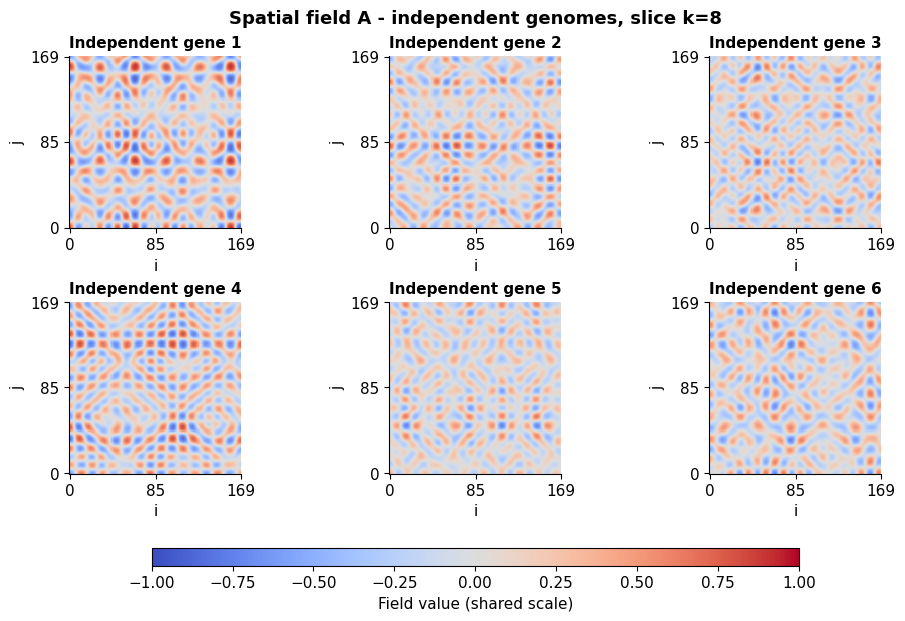

WindowsPath('generated_article_figures/extra_A_independent_genes_fixed_slice.png')

In [19]:
# A comparison 1/2 -6 independent random genes, same slice k.
A_COMPARISON_SLICE = example_dims[2] // 2
A_RANDOM_SEED = 2401
rng_a_independent = np.random.default_rng(A_RANDOM_SEED)
a_random_genes = [rng_a_independent.integers(0, 4, size=64) for _ in range(6)]
a_random_volumes = [A_volume(g, example_dims) for g in a_random_genes]
fig = plot_gene_comparison(
    a_random_volumes,
    [f"Independent gene {i+1}" for i in range(6)],
    k=A_COMPARISON_SLICE,
    title=f"Spatial field A - independent genomes, slice k={A_COMPARISON_SLICE}",
)
path_A_random = save_fig(fig, "extra_A_independent_genes_fixed_slice")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_A_random


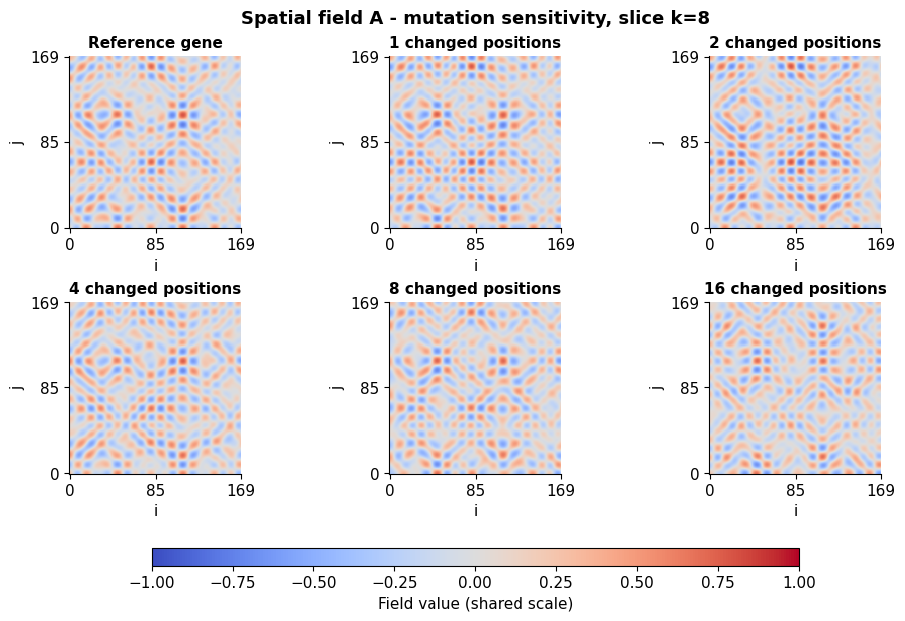

WindowsPath('generated_article_figures/extra_A_mutations_fixed_slice.png')

In [20]:
# A comparison 2/2 -same ancestral gene with exactly 0, 1, 2, 4, 8, 16 positions replaced.
# Shows how genetic perturbations reshape A without rescaling the colorbar.
A_MUTATION_SEED = 2402
rng_a_mut = np.random.default_rng(A_MUTATION_SEED)
a_ancestor = rng_a_mut.integers(0, 4, size=64)
a_changed_counts = [0, 1, 2, 4, 8, 16]
a_mutated_genes = [mutate_exact_positions(a_ancestor, n, rng_a_mut) for n in a_changed_counts]
a_mutated_volumes = [A_volume(g, example_dims) for g in a_mutated_genes]
fig = plot_gene_comparison(
    a_mutated_volumes,
    ["Reference gene" if n == 0 else f"{n} changed positions" for n in a_changed_counts],
    k=A_COMPARISON_SLICE,
    title=f"Spatial field A - mutation sensitivity, slice k={A_COMPARISON_SLICE}",
)
path_A_mutated = save_fig(fig, "extra_A_mutations_fixed_slice")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_A_mutated


### Cross-sections of A at fixed first-axis index i

Instead of the usual `A[:, :, k]` planes, these panels show **`A[i, :, :]`** for 16 positions distributed along the first axis. Within each panel, the horizontal coordinate is **j** and the vertical coordinate is **k**, so variation across all depth slices can be inspected in a single cross-section. The connection gene and the color scale $[-1,1]$ are held fixed throughout; these are not different genomes.


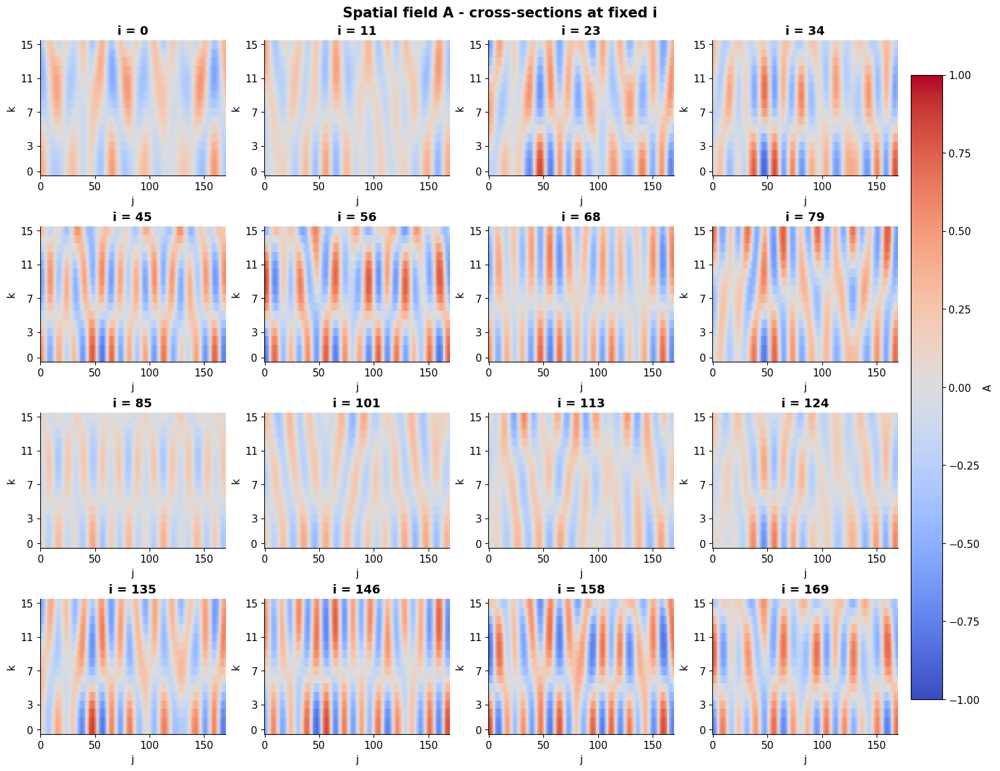

WindowsPath('generated_article_figures/extra_A_fixed_i_cross_sections.png')

In [21]:
# A cross-sections -first index fixed (A[i, :, :]); j and k vary within each panel.
# Sample 16 i-positions spanning the entire first axis, including the central plane.
I_CROSS_SECTION_COUNT = 16
I_CROSS_SECTION_INDICES = np.rint(
    np.linspace(0, example_dims[0] - 1, min(I_CROSS_SECTION_COUNT, example_dims[0]))
).astype(int)
I_CROSS_SECTION_INDICES[np.argmin(np.abs(I_CROSS_SECTION_INDICES - example_dims[0] // 2))] = example_dims[0] // 2
I_CROSS_SECTION_INDICES = np.unique(I_CROSS_SECTION_INDICES)

fig = heatmap_first_axis_cuts(
    A_x, I_CROSS_SECTION_INDICES,
    title="Spatial field A - cross-sections at fixed i",
    cmap="coolwarm", colorbar_label="A", vmin=-1, vmax=1,
)
path_A_i_cuts = save_fig(fig, "extra_A_fixed_i_cross_sections")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_A_i_cuts


## Extra visualizations -Connection-affinity $H$

In [22]:
# The same connection gene must determine both the source/target A fields
# and the coefficients of H; the source coordinate is fixed.
source = (example_dims[0] // 2, example_dims[1] // 2, example_dims[2] // 2)
coeffs = H_coefficients(spatial_genes["connections"])
H_vol = H_map(A_x, source, coeffs)
positive_mask = (H_vol > 0).astype(float)

print("Connection source neuron:", source)
print("H range:", float(H_vol.min()), float(H_vol.max()))


Connection source neuron: (85, 85, 8)
H range: -0.9999999999999992 0.9999999974678434


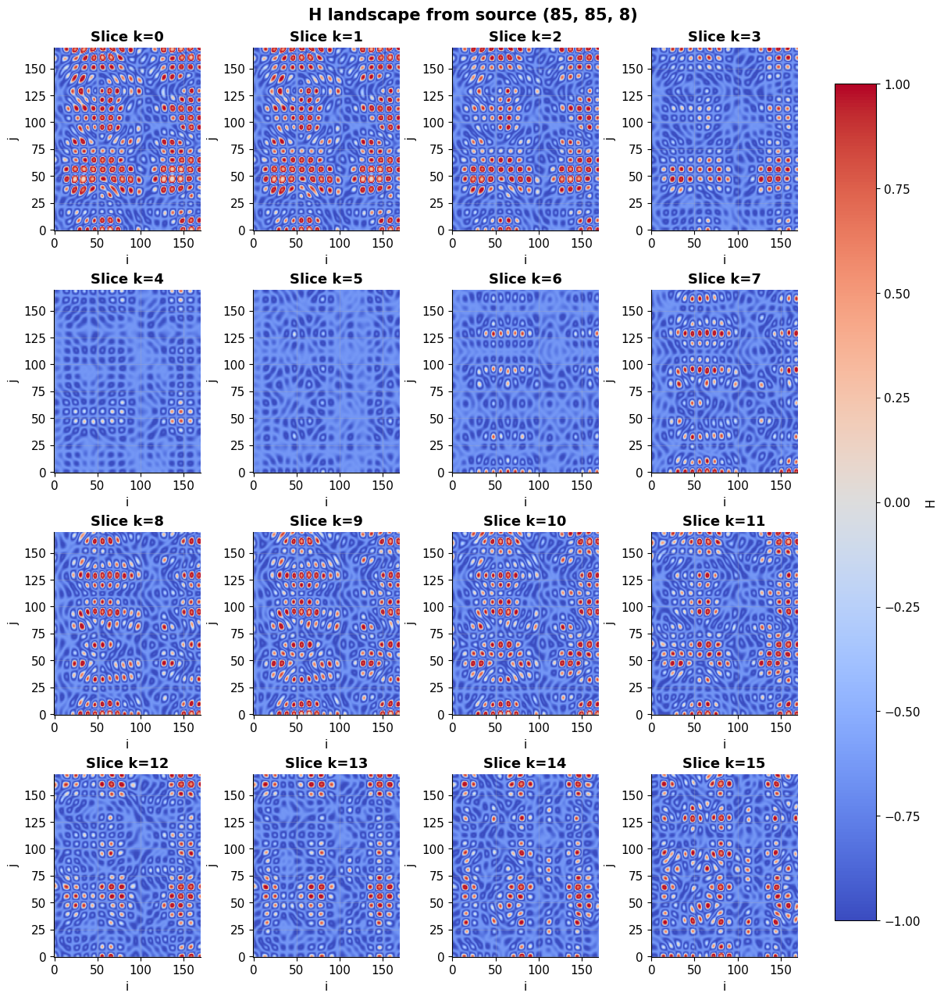

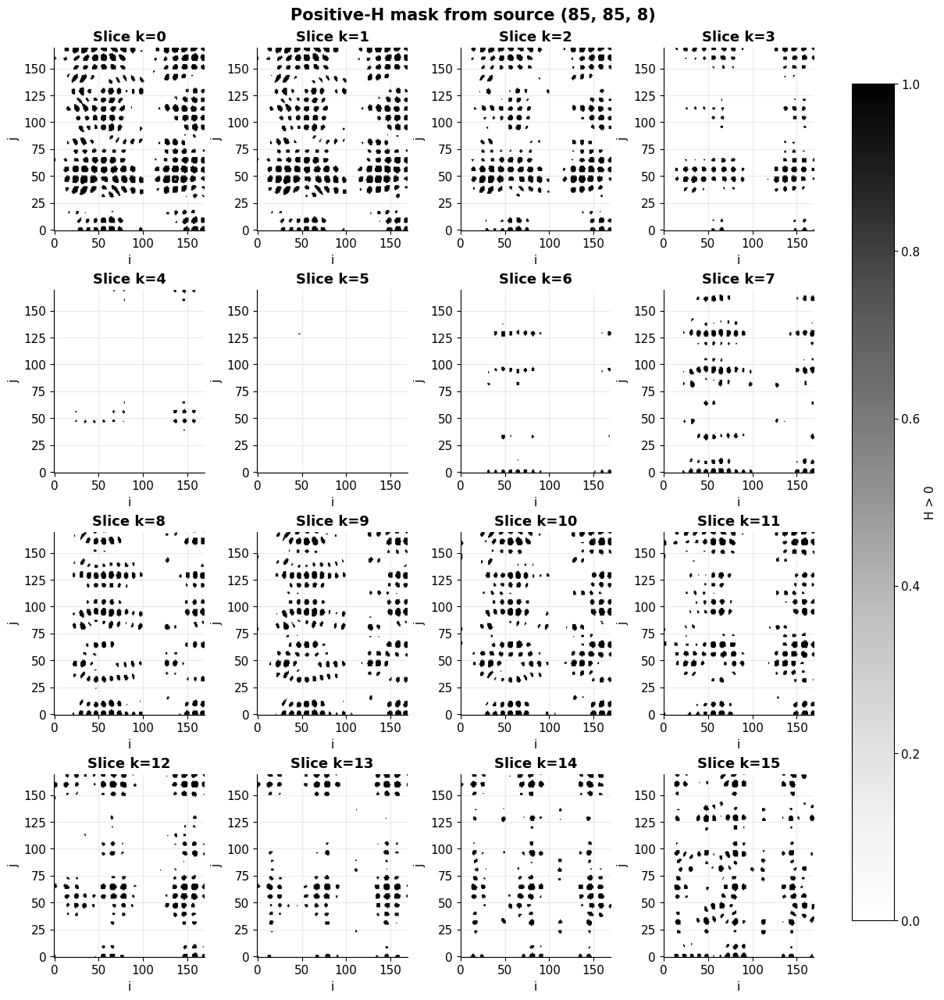

[WindowsPath('generated_article_figures/extra_H_heatmaps.png'),
 WindowsPath('generated_article_figures/extra_H_positive_mask.png')]

In [23]:

fig = heatmap_grid(H_vol, title=f"H landscape from source {source}", cmap="coolwarm", colorbar_label="H", vmin=-1, vmax=1)
path_H = save_fig(fig, "extra_H_heatmaps")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

fig = heatmap_grid(positive_mask, title=f"Positive-H mask from source {source}", cmap="Greys", colorbar_label="H > 0", vmin=0, vmax=1)
path_Hmask = save_fig(fig, "extra_H_positive_mask")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_H, path_Hmask]


### Comparing H across connection genes with the source held fixed

Both cells fix the source neuron at `H_FIXED_SOURCE` and show only target positions in slice `H_COMPARISON_SLICE`. For each different gene, **both** the spatial $A$ and the $H$ coefficients are recomputed from that gene. The black contour indicates $H=0$; the marked source cannot connect to itself. Positive $H$ alone does not guarantee a connection because geometric, role and capacity rules also apply.

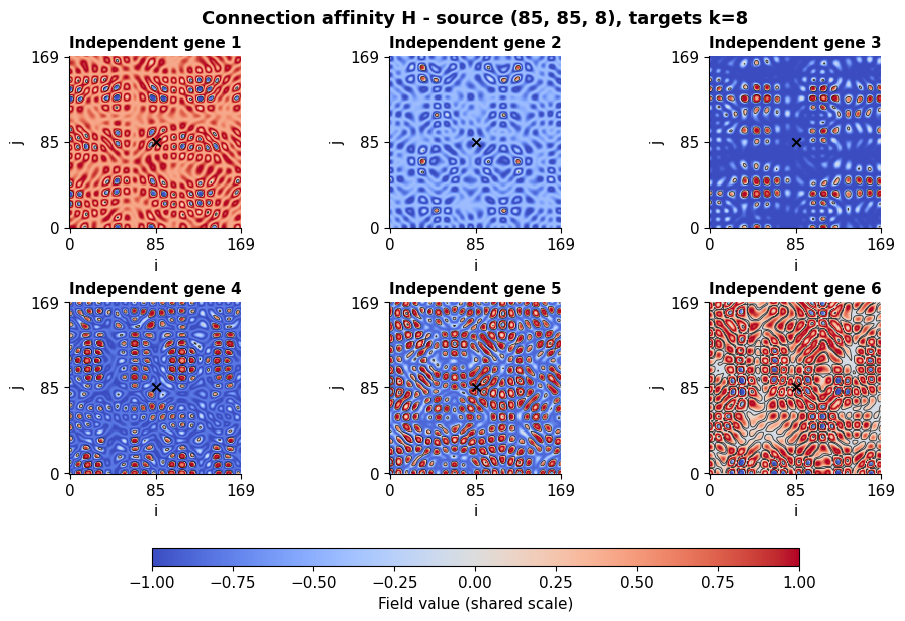

WindowsPath('generated_article_figures/extra_H_independent_genes_fixed_source.png')

In [24]:
# H comparison 1/2 -6 independent connection genes, ONE fixed source and target slice.
# For EACH gene, H coefficients and source/target A are computed from THAT SAME gene.
H_COMPARISON_SLICE = example_dims[2] // 2
H_FIXED_SOURCE = (example_dims[0] // 2, example_dims[1] // 2, H_COMPARISON_SLICE)
H_RANDOM_SEED = 3401
rng_h_independent = np.random.default_rng(H_RANDOM_SEED)
h_random_genes = [rng_h_independent.integers(0, 4, size=64) for _ in range(6)]
h_random_volumes = [
    H_map(A_volume(g, example_dims), H_FIXED_SOURCE, H_coefficients(g))
    for g in h_random_genes
]
fig = plot_gene_comparison(
    h_random_volumes,
    [f"Independent gene {i+1}" for i in range(6)],
    k=H_COMPARISON_SLICE,
    source=H_FIXED_SOURCE,
    zero_contour=True,
    title=f"Connection affinity H - source {H_FIXED_SOURCE}, targets k={H_COMPARISON_SLICE}",
)
path_H_random = save_fig(fig, "extra_H_independent_genes_fixed_source")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_H_random


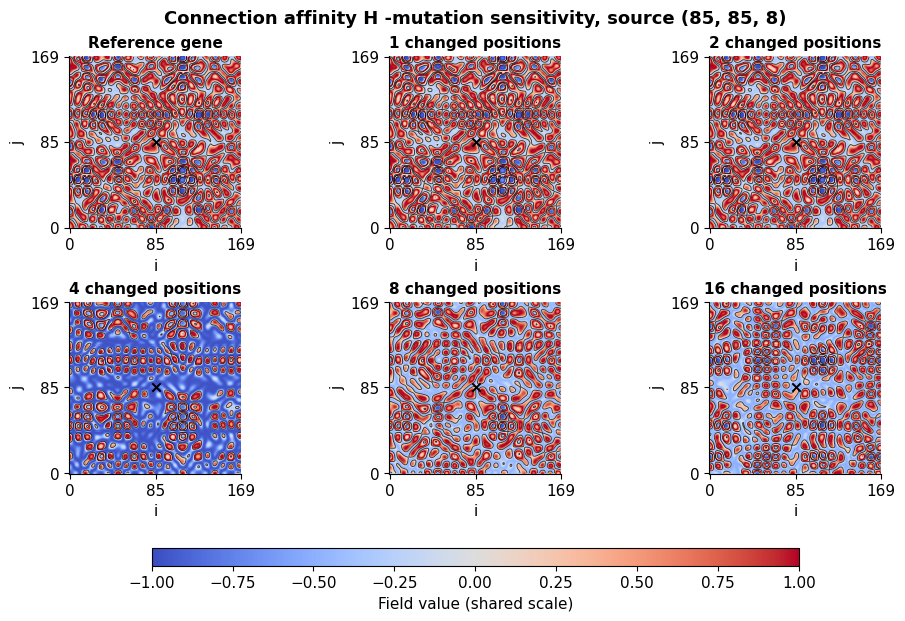

WindowsPath('generated_article_figures/extra_H_mutations_fixed_source.png')

In [25]:
# H comparison 2/2 -connection gene perturbations, with the SAME fixed source.
# The black contour is H=0 (H>0 is the basic initial affinity requirement).
H_MUTATION_SEED = 3402
rng_h_mut = np.random.default_rng(H_MUTATION_SEED)
h_ancestor = rng_h_mut.integers(0, 4, size=64)
h_changed_counts = [0, 1, 2, 4, 8, 16]
h_mutated_genes = [mutate_exact_positions(h_ancestor, n, rng_h_mut) for n in h_changed_counts]
h_mutated_volumes = [
    H_map(A_volume(g, example_dims), H_FIXED_SOURCE, H_coefficients(g))
    for g in h_mutated_genes
]
fig = plot_gene_comparison(
    h_mutated_volumes,
    ["Reference gene" if n == 0 else f"{n} changed positions" for n in h_changed_counts],
    k=H_COMPARISON_SLICE,
    source=H_FIXED_SOURCE,
    zero_contour=True,
    title=f"Connection affinity H -mutation sensitivity, source {H_FIXED_SOURCE}",
)
path_H_mutated = save_fig(fig, "extra_H_mutations_fixed_source")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_H_mutated


### Cross-sections of H at fixed first-axis index i

The panels show **`H[i, :, :]`** at exactly the same first-axis positions used for A, with **j** horizontal and **k** vertical. The connection gene and source neuron remain fixed for every panel. The shared $[-1,1]$ scale makes the signed affinity directly comparable across positions and between the A and H cross-section figures.


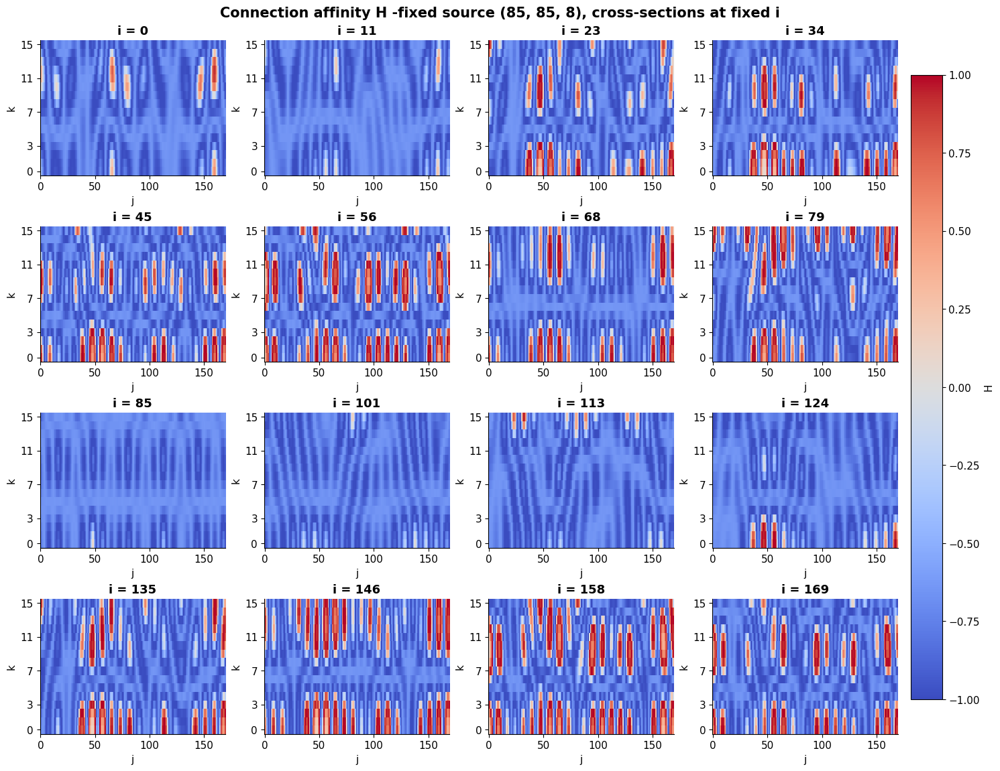

WindowsPath('generated_article_figures/extra_H_fixed_i_cross_sections.png')

In [26]:
# H cross-sections -first index fixed (H[i, :, :]); same i-positions as A.
# H_vol comes from the single fixed source and the same connection gene as A_x.
fig = heatmap_first_axis_cuts(
    H_vol, I_CROSS_SECTION_INDICES,
    title=f"Connection affinity H -fixed source {source}, cross-sections at fixed i",
    cmap="coolwarm", colorbar_label="H", vmin=-1, vmax=1,
)
path_H_i_cuts = save_fig(fig, "extra_H_fixed_i_cross_sections")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)
path_H_i_cuts


## Extra visualizations -3D fields and parameter transformations

The 3D view shows $A$ for the connections gene. In the scatter plots, each parameter is compared with its **own** gene-specific field $A$, not with the connections gene's field.

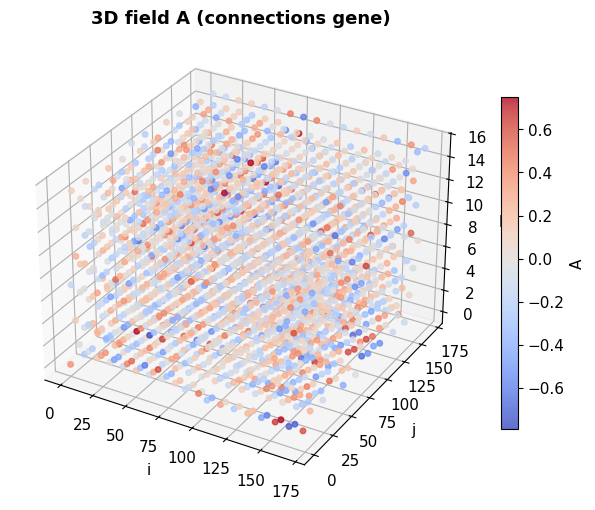

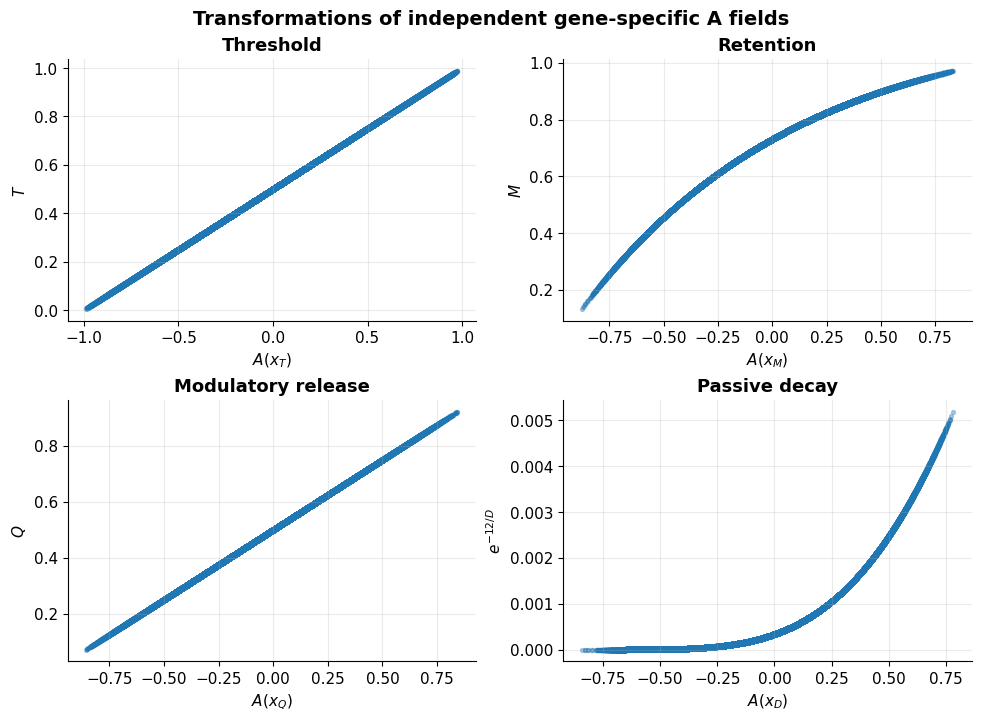

[WindowsPath('generated_article_figures/extra_A_3d_scatter.png'),
 WindowsPath('generated_article_figures/extra_cross_parameter_scatter.png')]

In [27]:
# 3D scatter of the CONNECTIONS gene's A field
I, J, K = example_dims
grid_i, grid_j, grid_k = np.meshgrid(np.arange(I), np.arange(J), np.arange(K), indexing='ij')
flat_A = A_x.ravel()
flat_i = grid_i.ravel()
flat_j = grid_j.ravel()
flat_k = grid_k.ravel()

sel = np.linspace(0, flat_A.size - 1, min(2500, flat_A.size), dtype=int)
fig = plt.figure(figsize=(7.6, 6.0))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(flat_i[sel], flat_j[sel], flat_k[sel], c=flat_A[sel], cmap='coolwarm', s=16, alpha=0.8)
ax.set_title("3D field A (connections gene)")
ax.set_xlabel('i')
ax.set_ylabel('j')
ax.set_zlabel('k')
fig.colorbar(sc, ax=ax, shrink=0.72, label='A')
path_A3d = save_fig(fig, "extra_A_3d_scatter")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

# Each x-axis uses the A field of the SAME gene as its y-axis parameter.
# This shows the actual nonlinear mapping, not a spurious reuse of one gene.
fig, axes = plt.subplots(2, 2, figsize=(9.7, 7.1), constrained_layout=True)
panels = [
    ("threshold", T_x, r"$A(x_T)$", r"$T$", "Threshold"),
    ("retention", M_x, r"$A(x_M)$", r"$M$", "Retention"),
    ("modulatory_release", Q_x, r"$A(x_Q)$", r"$Q$", "Modulatory release"),
    ("decay", decay_x, r"$A(x_D)$", r"$e^{-12/D}$", "Passive decay"),
]
for ax, (gene_name, result, x_label, y_label, title) in zip(axes.ravel(), panels):
    ax.scatter(A_fields[gene_name].ravel(), result.ravel(), s=8, alpha=0.35)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

fig.suptitle('Transformations of independent gene-specific A fields', fontsize=14, fontweight='bold')
path_scatter = save_fig(fig, "extra_cross_parameter_scatter")
if SHOW_FIGURES:
    plt.show()
plt.close(fig)

[path_A3d, path_scatter]


---

# Quantitative study: Is the current spatial field $A$ expressive enough?

**Scientific question.** The current 64-digit gene generates a spatial field by summing 64 products of cosines (four modes per axis). Are the apparent similarities between successive slices mostly an intensity rescaling, or do they represent genuine changes of spatial structure? Does the restriction affect $H$ or the ability of mutations to generate distinct phenotypes?

This section is a **paired, reproducible numerical experiment**, not a replacement for the model. It compares:

- **Current**: the exact spatial field $A$ already implemented in the Neurons notebook, with $L=16$, $\omega_r=\sqrt{r+1}$, 64 genetic coefficients and `tanh`.
- **Exploratory reference**: 64 oblique plane waves with *fixed*, reproducible frequencies and phases. It uses **the same 64 genetic digits** and the same initial $1/\sqrt{64}$ normalization. To avoid attributing differences in amplitude to spatial expressivity, the experiment can additionally apply a **fixed calibration factor per tested geometry** so that the expected spatial variance of the pre-`tanh` field matches the current formulation (the factor depends on the basis and size, never on the gene). This is an experimental control, not a proposed new modeling rule. This reference is *not* an endorsed reformulation or a validated implementation of Neurons; it is a controlled way to test what changes when the spatial basis is no longer the separable product of cosines. Its frequency distribution is an explicit modeling choice.

For each model, size and gene, we measure both $Z=\operatorname{atanh}(A)$ (before `tanh`) and $A$. For a fixed source neuron, $H$ is computed using exactly the same connection gene that generated $A$. We also use identical genes and mutation positions for both models, so the comparison is paired.

**Diagnostics:** adjacency and long-range slice correlation, best affine fit to a reference slice, SVD and effective rank, spatial roughness (all axes), diversity between unrelated genes, mutation response, and $H$ threshold statistics and spatial target discriminability.

**Interpretation restrictions:** the *current* $Z$ has matrix rank at most 4 along the slice axis **by construction**; this is not itself evidence that it is functionally insufficient. The rank bound does *not* apply exactly after `tanh`. No spatial diagnostic alone proves that a model can or cannot evolve learning or useful behavior. We can, however, decide whether the specific **"same image, changing intensity"** hypothesis is supported, and quantify the structural trade-offs of redesigning $A$.

## 1. Experimental settings and mathematical checks

Run this section after the notebook's **imports and model utilities** cells. You can run this section independently of the earlier (slow) figure-generation cells, provided the functions `A_volume`, `H_map`, `H_coefficients`, `H_value`, and `mutate_exact_positions` have been defined.

Increase `TEST_GENOMES` and `MUTATION_REPEATS` after checking the quick configuration. Two spatial sizes are included because conclusions for a brain with few slices may not hold for a deeper brain. All plots have compact previews and are exported to the same `OUTPUT_DIR` as the previous figures. The final cell produces **one JSON report**, which you can send back for review.

In [28]:
# ==== Experiment configuration (edit here) ====
EXPERIMENT_SEED = 20261030
TEST_SIZES = {
    "short": (32, 32, 16),
    "deep": (48, 48, 40),
}
TEST_GENOMES = 20               # independent 64-digit genes, reused in both models
MUTATION_REPEATS = 3            # mutant samples per gene and mutation count
MUTATION_COUNTS = (1, 2, 4, 8, 16)
BOOTSTRAP_REPEATS = 1000        # uncertainty intervals (resampling whole genomes)
MATCH_REFERENCE_VARIANCE = True  # match expected spatial variance of Z (not per gene)
SHOW_EXPERIMENT_PLOTS = True
SAVE_EXPERIMENT_PLOTS = True

from collections import defaultdict
import json

EXP_DIR = OUTPUT_DIR / "A_H_diagnostics"
EXP_DIR.mkdir(parents=True, exist_ok=True)
EXP_RNG = np.random.default_rng(EXPERIMENT_SEED)
EXP_GENES = EXP_RNG.integers(0, 4, (TEST_GENOMES, 64), dtype=np.int8)

# The same 64 mode indexes and the same fixed wave vectors/phases are used
# for every gene and both brain sizes. They are NOT genetically controlled.
ALT_MODE_SEED = 632064
_alt_rng = np.random.default_rng(ALT_MODE_SEED)
ALT_WAVE_VECTORS = _alt_rng.uniform(0.65, 2.05, size=(64, 3))
ALT_PHASES = _alt_rng.uniform(0.0, 2.0 * np.pi, size=64)


def make_spatial_basis(dims, model):
    """One (64, I*J*K) basis; fixed for a given size and formulation."""
    I, J, K = map(int, dims)
    if min(I, J, K) < 2:
        raise ValueError("Dimensions must be at least 2")
    nvox = I * J * K
    B = np.empty((64, nvox), dtype=np.float64)
    i = np.arange(I, dtype=float)[:, None, None] / 16.0
    j = np.arange(J, dtype=float)[None, :, None] / 16.0
    k = np.arange(K, dtype=float)[None, None, :] / 16.0
    if model == "current":
        freqs = np.sqrt(np.arange(1, 5, dtype=float))
        bx = np.cos(np.pi * freqs[:, None] * np.arange(I) / 16.0)
        by = np.cos(np.pi * freqs[:, None] * np.arange(J) / 16.0)
        bz = np.cos(np.pi * freqs[:, None] * np.arange(K) / 16.0)
        for r in range(4):
            for s in range(4):
                for q in range(4):
                    t = q + 4*s + 16*r
                    B[t] = (bx[r, :, None, None] * by[s, None, :, None]
                            * bz[q, None, None, :]).ravel() / 8.0
    elif model == "oblique_reference":
        for t in range(64):
            u, v, w = ALT_WAVE_VECTORS[t]
            B[t] = np.cos(np.pi * (u*i + v*j + w*k) + ALT_PHASES[t]).ravel() / 8.0
    else:
        raise ValueError("Unknown model")
    return B


def field_from_basis(gene, basis, dims):
    """Return (pre-tanh Z, final A). Gene digits map to -1,-1/3,1/3,1."""
    alpha = (2.0 * np.asarray(gene, dtype=np.float64) / 3.0 - 1.0)
    Z = np.einsum('t,tn->n', alpha, basis, optimize=True).reshape(dims)
    return Z, np.tanh(Z)


def exp_corr(x, y):
    x, y = np.asarray(x, dtype=float).ravel(), np.asarray(y, dtype=float).ravel()
    x = x - x.mean()
    y = y - y.mean()
    den = np.linalg.norm(x) * np.linalg.norm(y)
    return float(x @ y / den) if den > 1e-14 else float('nan')


def exp_mean(values):
    values = np.asarray(values, dtype=float)
    return float(np.mean(values[np.isfinite(values)])) if np.isfinite(values).any() else float('nan')


def exp_sources(dims):
    I, J, K = dims
    return [
        (I // 2, J // 2, K // 2),
        (I // 4, J // 4, K // 4),
        (3*I // 4, J // 3, 2*K // 3),
    ]


# Sanity checks: exact current field, correct gene coupling in H,
# and the exact rank bound BEFORE tanh.
_check_gene = EXP_GENES[0]
_check_dims = (9, 11, 7)
_bcur = make_spatial_basis(_check_dims, "current")
_zcheck, _acheck = field_from_basis(_check_gene, _bcur, _check_dims)
assert np.allclose(_acheck, A_volume(_check_gene, _check_dims), atol=2e-14, rtol=2e-14)
assert np.linalg.matrix_rank(_zcheck.reshape(-1, _check_dims[2]), tol=1e-10) <= 4
assert make_spatial_basis(_check_dims, "oblique_reference").shape == (64, np.prod(_check_dims))
assert np.allclose(H_map(_acheck, (4, 4, 3), H_coefficients(_check_gene)),
                   H_value(_acheck[4, 4, 3], _acheck, H_coefficients(_check_gene)))
print("Checks passed: current A matches the original notebook, rank(Z) <= 4, and H uses the same gene.")
print(f"Settings: {TEST_GENOMES} genes, sizes {TEST_SIZES}, mutations {MUTATION_COUNTS} x {MUTATION_REPEATS}")

Checks passed: current A matches the original notebook, rank(Z) <= 4, and H uses the same gene.
Settings: 20 genes, sizes {'short': (32, 32, 16), 'deep': (48, 48, 40)}, mutations (1, 2, 4, 8, 16) x 3


## 2. Slice similarity, effective dimension, smoothness, and independent genomes

We distinguish **nearby slices** (where high similarity is expected for any smooth field) from **widely separated slices**. The `far_slice_R2` metric is the mean $r^2$ between each slice and a central reference slice, restricted to slices at least one quarter of the depth away. Because $r^2$ allows a negative slope, it measures similarity after allowing a change of scale *and inversion*. The signed correlations are reported separately.

The **SVD** applies to the spatially centered matrix with shape $(IJ)\times K$ (one column per slice). The first explained fraction near 1 indicates approximate rank one; `effective_rank` is the participation ratio of the squared singular values, not the literal matrix rank. The SVD is computed separately for $Z$ and for $A=\tanh(Z)$.

`roughness_i/j/k` is RMS difference between adjacent spatial positions divided by the standard deviation of the field. This is a dimensionless descriptive statistic, **not** a judgment that more roughness is better. Values are computed on the actual lattice, not an interpolated image.

In [29]:
def slice_metrics(volume):
    """Measure true spatial variation and approximate rank-one behavior."""
    volume = np.asarray(volume, dtype=float)
    I, J, K = volume.shape
    M = volume.reshape(I*J, K)
    C = M - M.mean(axis=0, keepdims=True)
    sing = np.linalg.svd(C, full_matrices=False, compute_uv=False)
    energy = sing**2
    total = float(energy.sum())
    fractions = energy / total if total > 0 else np.zeros_like(energy)
    eff_rank = float(total**2 / np.sum(energy**2)) if total > 0 else 0.0
    ref_k = K // 2
    adj = [exp_corr(M[:, k], M[:, k+1]) for k in range(K-1)]
    far = [exp_corr(M[:, k], M[:, ref_k])
           for k in range(K) if abs(k-ref_k) >= max(2, K//4)]
    spatial_std = float(volume.std())
    scales = [float(np.sqrt(np.mean(np.diff(volume, axis=axis)**2))
                    / max(spatial_std, 1e-12)) for axis in range(3)]
    return {
        "ev1": float(fractions[0]),
        "ev4": float(fractions[:4].sum()),
        "effective_rank": eff_rank,
        "adjacent_corr": exp_mean(adj),
        "far_slice_R2": exp_mean(np.square(far)),
        "far_signed_corr": exp_mean(far),
        "far_negative_fraction": exp_mean(np.asarray(far) < 0) if far else float('nan'),
        "roughness_i": scales[0], "roughness_j": scales[1], "roughness_k": scales[2],
        "spatial_std": spatial_std,
    }


def h_metrics(A, gene, sources):
    """H>0 is eligibility only; this does NOT simulate actual wiring/rescue."""
    coeff = H_coefficients(gene)
    rates, spreads, boundary_rates, h_maps = [], [], [], []
    for src in sources:
        H = H_map(A, src, coeff)
        H = np.array(H, copy=True)
        H[src] = np.nan  # no self-connection
        valid = np.isfinite(H)
        rates.append(float(np.mean(H[valid] > 0)))
        spreads.append(float(np.std(H[valid])))
        edges = []
        for axis in range(3):
            lo = np.take(H, np.arange(H.shape[axis]-1), axis=axis)
            hi = np.take(H, np.arange(1, H.shape[axis]), axis=axis)
            valid_pairs = np.isfinite(lo) & np.isfinite(hi)
            edges.append(float(np.mean((lo[valid_pairs] > 0) != (hi[valid_pairs] > 0))))
        boundary_rates.append(float(np.mean(edges)))
        h_maps.append(H)
    across_sources = []
    for i in range(len(h_maps)):
        for j in range(i+1, len(h_maps)):
            common = np.isfinite(h_maps[i]) & np.isfinite(h_maps[j])
            across_sources.append(exp_corr(h_maps[i][common], h_maps[j][common]))
    return {
        "h_positive_fraction": exp_mean(rates),
        "h_std": exp_mean(spreads),
        "h_sign_boundary_fraction": exp_mean(boundary_rates),
        "h_between_source_abs_corr": exp_mean(np.abs(across_sources)),
    }


EXPERIMENTS = {}
for size_name, dims in TEST_SIZES.items():
    basis = {kind: make_spatial_basis(dims, kind)
             for kind in ("current", "oblique_reference")}
    expected_var_current = float(np.var(basis["current"], axis=1).sum())
    expected_var_alt = float(np.var(basis["oblique_reference"], axis=1).sum())
    alt_scale = (np.sqrt(expected_var_current / expected_var_alt)
                 if MATCH_REFERENCE_VARIANCE else 1.0)
    basis["oblique_reference"] *= alt_scale
    EXPERIMENTS[size_name] = {"dims": dims, "basis": basis,
                              "alt_calibration_factor": alt_scale, "models": {}}
    print(f"Reference calibration for {size_name}: {alt_scale:.4f}")
    for kind in basis:
        rows, Zs, As, Hs = [], [], [], []
        sources = exp_sources(dims)
        for gene in EXP_GENES:
            Z, A = field_from_basis(gene, basis[kind], dims)
            stats_z = slice_metrics(Z)
            stats_a = slice_metrics(A)
            stats_h = h_metrics(A, gene, sources)
            row = {**{f"Z_{key}": val for key, val in stats_z.items()},
                   **{f"A_{key}": val for key, val in stats_a.items()}, **stats_h}
            rows.append(row)
            Zs.append(Z)
            As.append(A)
            Hs.append(H_map(A, sources[0], H_coefficients(gene)))
        # Correlations across *independent* genes (same spatial positions).
        a_between, h_between = [], []
        for i in range(len(As)):
            for j in range(i+1, len(As)):
                a_between.append(exp_corr(As[i], As[j]))
                h_between.append(exp_corr(Hs[i], Hs[j]))
        EXPERIMENTS[size_name]["models"][kind] = {
            "rows": rows, "Zs": Zs, "As": As,
            "between_A_corr": a_between,
            "between_H_corr": h_between,
        }
        print(f"{size_name:5s} {kind:17s}: "
              f"mean adjacent A r={exp_mean([r['A_adjacent_corr'] for r in rows]):.3f}, "
              f"mean distant A R²={exp_mean([r['A_far_slice_R2'] for r in rows]):.3f}, "
              f"mean effective rank A={exp_mean([r['A_effective_rank'] for r in rows]):.2f}")

Reference calibration for short: 0.5040
short current          : mean adjacent A r=0.934, mean distant A R²=0.385, mean effective rank A=1.63
short oblique_reference: mean adjacent A r=0.963, mean distant A R²=0.124, mean effective rank A=2.30
Reference calibration for deep: 0.5158
deep  current          : mean adjacent A r=0.944, mean distant A R²=0.238, mean effective rank A=3.01
deep  oblique_reference: mean adjacent A r=0.963, mean distant A R²=0.240, mean effective rank A=3.55


## 3. Visual diagnosis: correlation matrices, rank profiles, and independent genomes

The plots below show one **predeclared representative gene** (index 0), to avoid selecting visually convenient samples. The quantitative decisions should instead use the aggregate statistics of **all** genomes and both brain sizes. Correlation heatmaps and SVD apply to the same volume and use identical axes/scales for both formulations.

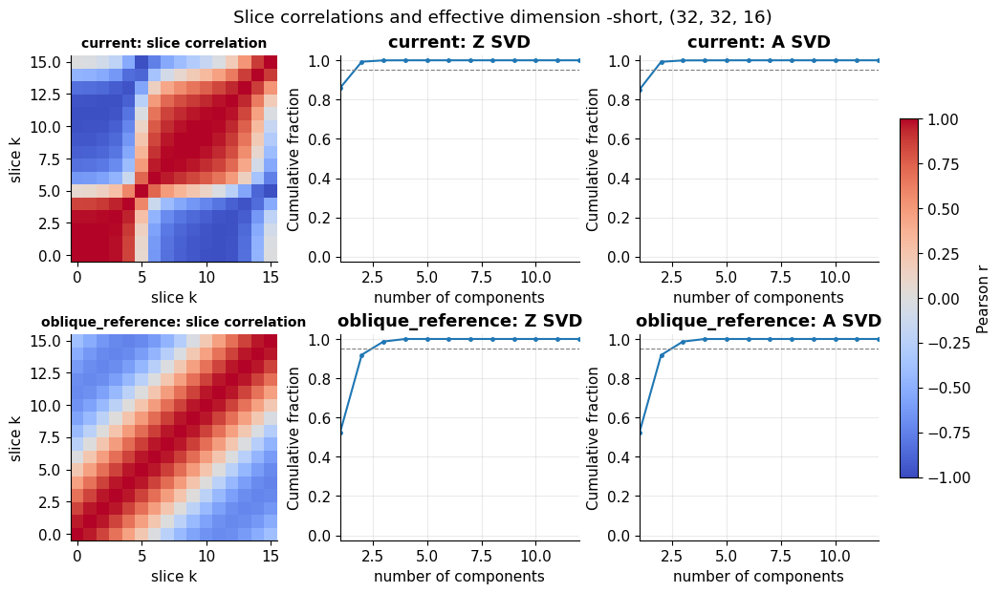

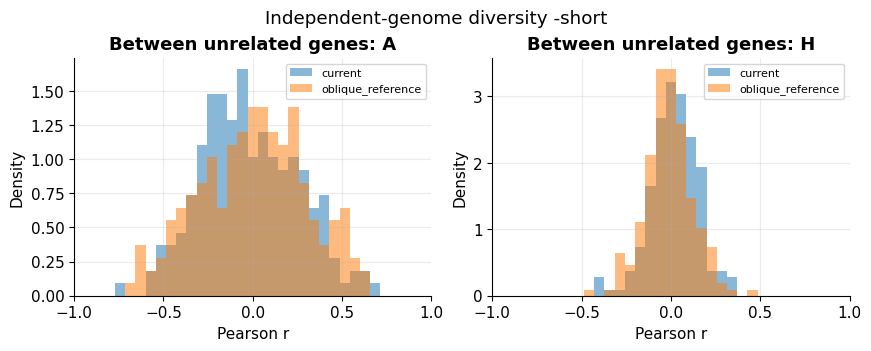

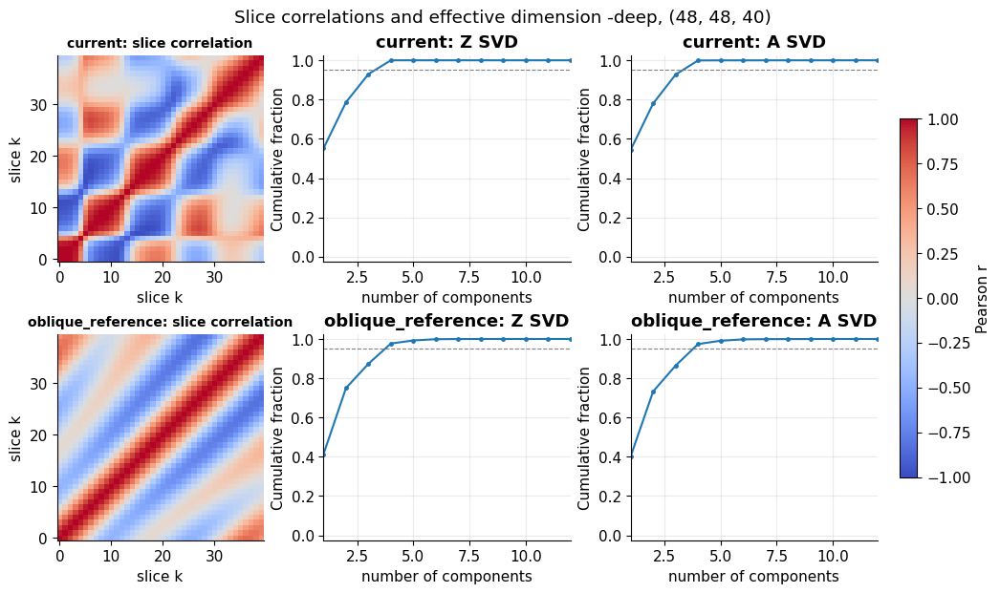

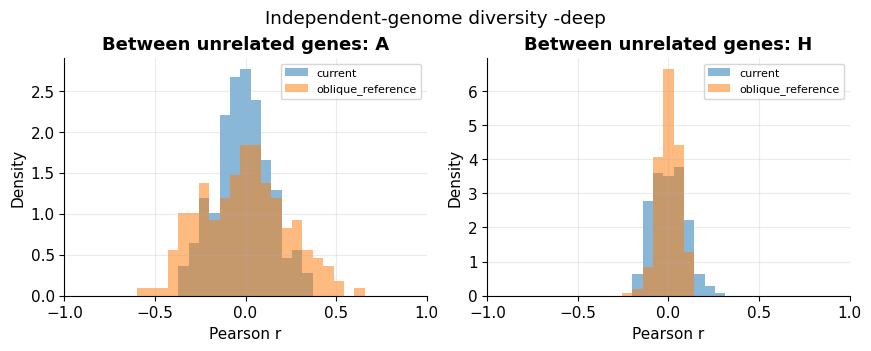

In [30]:
def exp_save_and_show(fig, stem):
    if SAVE_EXPERIMENT_PLOTS:
        fig.savefig(EXP_DIR / f"{stem}.png", dpi=EXPORT_DPI, bbox_inches="tight")
    if SHOW_EXPERIMENT_PLOTS:
        plt.show()
    plt.close(fig)


for size_name, record in EXPERIMENTS.items():
    dims = record["dims"]
    fig, axes = plt.subplots(2, 3, figsize=(10.3, 6.1), constrained_layout=True)
    for row_idx, kind in enumerate(("current", "oblique_reference")):
        A = record["models"][kind]["As"][0]
        Z = record["models"][kind]["Zs"][0]
        K = dims[2]
        mats = A.reshape(-1, K).T
        corr = np.corrcoef(mats)
        ax = axes[row_idx, 0]
        im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, origin="lower")
        ax.set_title(f"{kind}: slice correlation", fontsize=10)
        ax.set_xlabel("slice k")
        ax.set_ylabel("slice k")
        ax.grid(False)
        for col_idx, vol in enumerate((Z, A), start=1):
            C = vol.reshape(-1, K)
            C = C - C.mean(axis=0, keepdims=True)
            s = np.linalg.svd(C, compute_uv=False)
            e = s*s
            frac = e/e.sum()
            ax = axes[row_idx, col_idx]
            ax.plot(np.arange(1, len(frac)+1), np.cumsum(frac), marker="o", markersize=2.5)
            ax.axhline(0.95, linestyle="--", linewidth=0.8, color="gray")
            ax.set_xlim(1, min(12, K))
            ax.set_ylim(-0.025, 1.025)
            ax.set_title(f"{kind}: {('Z' if col_idx==1 else 'A')} SVD")
            ax.set_xlabel("number of components")
            ax.set_ylabel("Cumulative fraction")
    fig.colorbar(im, ax=axes.ravel().tolist(), location="right", shrink=0.74,
                 fraction=0.025, pad=0.025, label="Pearson r")
    fig.suptitle(f"Slice correlations and effective dimension -{size_name}, {dims}")
    exp_save_and_show(fig, f"slice_rank_{size_name}")

    # Distribution of pairwise correlations between DIFFERENT genes.
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4), constrained_layout=True)
    for ax, label, field in zip(axes, ("A", "H"), ("between_A_corr", "between_H_corr")):
        for kind in ("current", "oblique_reference"):
            values = record["models"][kind][field]
            ax.hist(values, bins=np.linspace(-1, 1, 36), alpha=0.53,
                    label=kind, density=True)
        ax.set_title(f"Between unrelated genes: {label}")
        ax.set_xlim(-1, 1)
        ax.set_xlabel("Pearson r")
        ax.set_ylabel("Density")
        ax.legend(fontsize=8)
    fig.suptitle(f"Independent-genome diversity -{size_name}")
    exp_save_and_show(fig, f"between_genomes_{size_name}")

## 4. Genetic changes and phenotypic sensitivity

For every independent base gene, mutate **exactly** 1, 2, 4, 8, or 16 positions, replacing each chosen digit by a *different* value in $\{0,1,2,3\}$. Mutants are generated once and reused identically for the two spatial bases. The same source coordinates are used for the $H$ comparisons. The measured responses are:

- **Relative A RMS**: $\mathrm{RMSE}(A_{\mathrm{mut}},A_{\mathrm{base}})/\mathrm{SD}(A_{\mathrm{base}})$; note this compares final fields, not the unbounded $Z$.
- **H sign flips**: fraction of target voxels whose membership in the set $H>0$ changes (excluding the source itself).
- **H RMS difference**: RMS affinity difference at the same targets.
- **Normalized genetic $L_1$ distance**: $\sum_t|x_t-y_t|/(3\cdot64)$.

Increased sensitivity is **neither automatically beneficial nor automatically harmful**: tiny mutations that destroy large regions can impede heredity, while changes that are too small may reduce evolvability.

short current mutation cases: 300
short oblique_reference mutation cases: 300


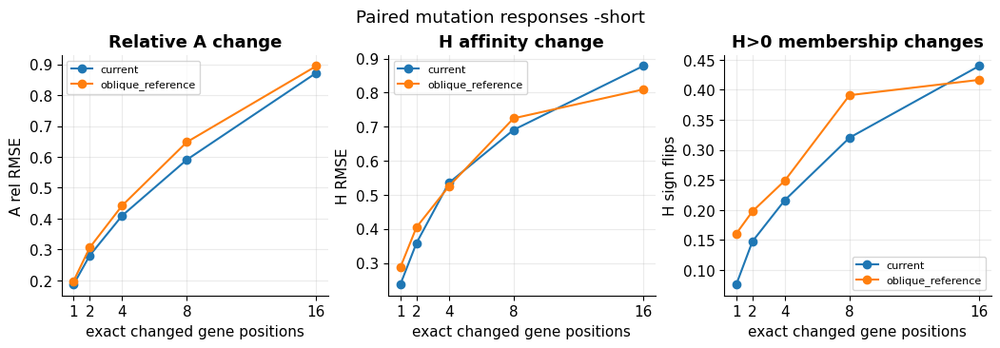

deep current mutation cases: 300
deep oblique_reference mutation cases: 300


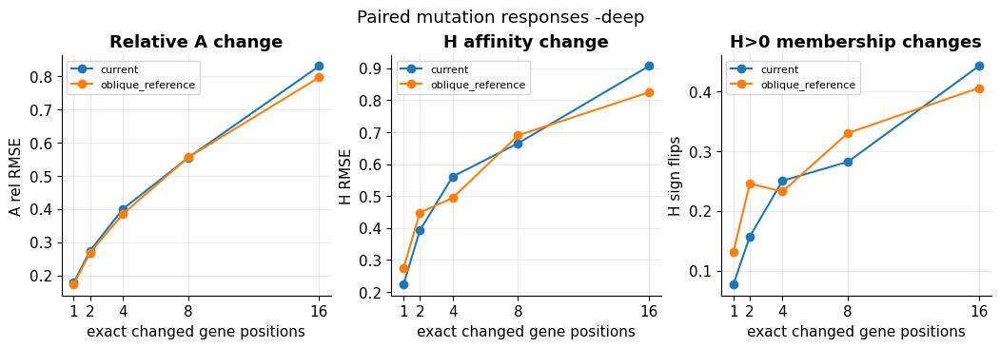

In [31]:
MUTATION_RESULTS = {}
# Re-generate mutations deterministically and re-use them for both fields.
_mut_rng = np.random.default_rng(EXPERIMENT_SEED + 55)
mutations = []
for gi, base_gene in enumerate(EXP_GENES):
    for count in MUTATION_COUNTS:
        for repeat in range(MUTATION_REPEATS):
            mutant = mutate_exact_positions(base_gene, count, _mut_rng)
            mutations.append((gi, count, repeat, mutant))

for size_name, record in EXPERIMENTS.items():
    dims = record["dims"]
    src = exp_sources(dims)[0]  # one fixed source in this test
    MUTATION_RESULTS[size_name] = {}
    for kind in ("current", "oblique_reference"):
        basis = record["basis"][kind]
        baseline_A = record["models"][kind]["As"]
        baseline_H = [H_map(A, src, H_coefficients(g))
                      for A, g in zip(baseline_A, EXP_GENES)]
        records = []
        for gi, count, repeat, mutant in mutations:
            _, new_A = field_from_basis(mutant, basis, dims)
            base_A = baseline_A[gi]
            new_H = H_map(new_A, src, H_coefficients(mutant))
            base_H = baseline_H[gi]
            valid = np.ones(dims, dtype=bool)
            valid[src] = False
            records.append({
                "gene_index": gi, "changed": count, "repeat": repeat,
                "gene_l1": float(np.abs(EXP_GENES[gi].astype(int) - mutant.astype(int)).sum() / 192.0),
                "A_rel_RMSE": float(np.sqrt(np.mean((new_A-base_A)**2)) / max(np.std(base_A), 1e-12)),
                "H_RMSE": float(np.sqrt(np.mean((new_H[valid]-base_H[valid])**2))),
                "H_sign_flips": float(np.mean((new_H[valid] > 0) != (base_H[valid] > 0))),
            })
        MUTATION_RESULTS[size_name][kind] = records
        print(size_name, kind, "mutation cases:", len(records))

    fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.55), constrained_layout=True)
    metrics = ("A_rel_RMSE", "H_RMSE", "H_sign_flips")
    titles = ("Relative A change", "H affinity change", "H>0 membership changes")
    for ax, metric, title in zip(axes, metrics, titles):
        for kind in ("current", "oblique_reference"):
            rows = MUTATION_RESULTS[size_name][kind]
            ys = [exp_mean([r[metric] for r in rows if r["changed"] == count])
                  for count in MUTATION_COUNTS]
            ax.plot(MUTATION_COUNTS, ys, marker="o", label=kind)
        ax.set_title(title)
        ax.set_xlabel("exact changed gene positions")
        ax.set_xticks(MUTATION_COUNTS)
        ax.set_ylabel(metric.replace("_", " "))
        ax.legend(fontsize=8)
    fig.suptitle(f"Paired mutation responses -{size_name}")
    exp_save_and_show(fig, f"mutation_responses_{size_name}")

## 5. How much positional information can $H$ use?

A key structural limitation follows directly from the definition: **for a fixed source and fixed connection gene, $H$ is a scalar function only of the target's value of $A$**. Two targets with exactly the same $A$ therefore have exactly the same affinity $H$, irrespective of the distance between them. A different basis for $A$ changes *which positions* share similar $A$, but **does not remove this constraint in $H$**.

We test this numerically by sorting the targets by $A$, finding nearby values of $A$ at *spatially distant* locations, and measuring the corresponding differences in $H$. We also summarize how balanced the $H>0$ eligibility set is across random genes. The set $H>0$ is **not** the actual generated graph: spatial candidate restrictions, connection caps, roles, ranking, and rescue still matter.

short current          : distant near-equal-A pairs 13285, mean |delta H| 0.000311
short oblique_reference: distant near-equal-A pairs 12422, mean |delta H| 0.000206
deep  current          : distant near-equal-A pairs 40000, mean |delta H| 0.000077
deep  oblique_reference: distant near-equal-A pairs 40000, mean |delta H| 0.000052


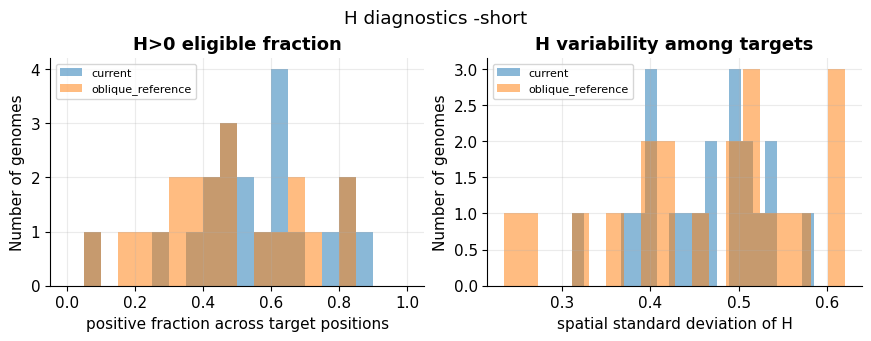

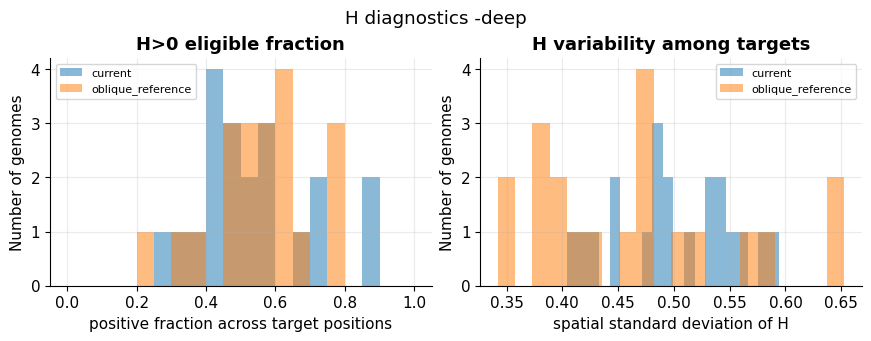

In [32]:
def similar_energy_far_targets(A, H, max_pairs=2000):
    """Adjacent sorted A values, but target coordinates far apart in the mesh."""
    dims = A.shape
    flat_a = A.ravel()
    flat_h = H.ravel()
    order = np.argsort(flat_a)
    left, right = order[:-1], order[1:]
    coord_l = np.asarray(np.unravel_index(left, dims)).T
    coord_r = np.asarray(np.unravel_index(right, dims)).T
    min_manhattan = 0.6 * sum(dims)
    far = np.sum(np.abs(coord_l-coord_r), axis=1) >= min_manhattan
    close = np.abs(flat_a[left]-flat_a[right]) <= 0.001
    indices = np.flatnonzero(far & close)
    if indices.size > max_pairs:
        indices = indices[np.linspace(0, len(indices)-1, max_pairs, dtype=int)]
    return {
        "count": int(len(indices)),
        "mean_delta_A": float(np.mean(np.abs(flat_a[left[indices]]-flat_a[right[indices]]))) if len(indices) else None,
        "mean_delta_H": float(np.mean(np.abs(flat_h[left[indices]]-flat_h[right[indices]]))) if len(indices) else None,
    }

ISOENERGY_RESULTS = {}
for size_name, record in EXPERIMENTS.items():
    ISOENERGY_RESULTS[size_name] = {}
    src = exp_sources(record["dims"])[0]
    for kind in ("current", "oblique_reference"):
        iso = []
        for gene, A in zip(EXP_GENES, record["models"][kind]["As"]):
            H = H_map(A, src, H_coefficients(gene))
            iso.append(similar_energy_far_targets(A, H))
        ISOENERGY_RESULTS[size_name][kind] = iso
        print(f"{size_name:5s} {kind:17s}: "
              f"distant near-equal-A pairs {sum(r['count'] for r in iso)}, "
              f"mean |delta H| {exp_mean([r['mean_delta_H'] for r in iso if r['count']]):.6f}")

# Show distribution of H-positive fractions and H spatial variation across genes.
for size_name, record in EXPERIMENTS.items():
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.3), constrained_layout=True)
    for kind in ("current", "oblique_reference"):
        rows = record["models"][kind]["rows"]
        axes[0].hist([r["h_positive_fraction"] for r in rows],
                     bins=np.linspace(0, 1, 21), alpha=0.52, label=kind)
        axes[1].hist([r["h_std"] for r in rows],
                     bins=20, alpha=0.52, label=kind)
    axes[0].set_title("H>0 eligible fraction")
    axes[0].set_xlabel("positive fraction across target positions")
    axes[1].set_title("H variability among targets")
    axes[1].set_xlabel("spatial standard deviation of H")
    for ax in axes:
        ax.set_ylabel("Number of genomes")
        ax.legend(fontsize=8)
    fig.suptitle(f"H diagnostics -{size_name}")
    exp_save_and_show(fig, f"H_statistics_{size_name}")

## 6. Results with uncertainty and a portable JSON report

The table below reports **means over independent genomes** for each field, plus 95% *paired bootstrap* intervals for the difference `(oblique_reference - current)`. Resampling is performed at the **genome level**: slices and mutation trials from the same genome are not treated as independent biological replicates. These intervals describe the sampling uncertainty for the stated random-gene experiment, **not** uncertainty about evolutionary success.

The summary deliberately does not issue a binary "better/worse" verdict. Relevant questions for our next discussion are: Does the present $A$ genuinely act like a scaled copy across *distant* slices? Is any increase in spatial diversity accompanied by excessive roughness or mutation sensitivity? Does $H$ distinguish enough target positions, or does its scalar bottleneck dominate regardless of the choice of $A$? To judge actual **evolutionary usefulness**, an additional controlled evolutionary experiment would ultimately be required.

In [33]:
def paired_bootstrap_ci(current, alternative, n_boot=1000, seed=0):
    a, b = np.asarray(current, dtype=float), np.asarray(alternative, dtype=float)
    good = np.isfinite(a) & np.isfinite(b)
    d = b[good] - a[good]
    if not len(d):
        return [None, None]
    rg = np.random.default_rng(seed)
    resamples = rg.integers(0, len(d), size=(n_boot, len(d)))
    means = d[resamples].mean(axis=1)
    return [float(x) for x in np.quantile(means, (0.025, 0.975))]


REPORT_METRICS = (
    "Z_ev1", "Z_ev4", "Z_effective_rank", "A_ev1", "A_ev4", "A_effective_rank",
    "A_adjacent_corr", "A_far_slice_R2", "A_far_signed_corr",
    "A_roughness_i", "A_roughness_j", "A_roughness_k", "A_spatial_std",
    "h_positive_fraction", "h_std", "h_sign_boundary_fraction",
    "h_between_source_abs_corr",
)

report = {
    "purpose": "Testing spatial-field expressivity and H affinity, not evolutionary fitness",
    "seed": EXPERIMENT_SEED,
    "alternative_mode_seed": ALT_MODE_SEED,
    "alternative_description": "64 fixed oblique plane waves; each axis frequency U[0.65,2.05], phase U[0,2pi], same alpha digits and 1/sqrt(64) normalization before optional basis-variance calibration",
    "match_reference_variance": MATCH_REFERENCE_VARIANCE,
    "settings": {
        "sizes": {name: list(dims) for name, dims in TEST_SIZES.items()},
        "genomes": TEST_GENOMES,
        "mutation_repeats": MUTATION_REPEATS,
        "mutation_counts": list(MUTATION_COUNTS),
        "bootstrap_repeats": BOOTSTRAP_REPEATS,
        "gene_strings": ["".join(map(str, gene)) for gene in EXP_GENES],
    },
    "results": {},
}

for size_idx, (size_name, record) in enumerate(EXPERIMENTS.items()):
    rows_c = record["models"]["current"]["rows"]
    rows_o = record["models"]["oblique_reference"]["rows"]
    metrics_out = {}
    print("\n" + "="*87)
    print(f"SIZE: {size_name} {record['dims']}   |   paired random genomes = {TEST_GENOMES}")
    print("metric                            current       oblique      diff95% CI [lower, upper]")
    print("-"*87)
    for idx, metric in enumerate(REPORT_METRICS):
        vals_c = [r[metric] for r in rows_c]
        vals_o = [r[metric] for r in rows_o]
        ci = paired_bootstrap_ci(vals_c, vals_o, BOOTSTRAP_REPEATS,
                                  seed=EXPERIMENT_SEED + 1500 + 100*size_idx + idx)
        cmean, omean = exp_mean(vals_c), exp_mean(vals_o)
        metrics_out[metric] = {
            "mean_current": cmean,
            "mean_oblique_reference": omean,
            "oblique_minus_current_CI95": ci,
            "per_genome_current": vals_c,
            "per_genome_oblique_reference": vals_o,
        }
        print(f"{metric:32s} {cmean:9.4f} {omean:12.4f}  [{ci[0]:8.4f},{ci[1]:8.4f}]")

    between = {}
    for metric in ("between_A_corr", "between_H_corr"):
        vc = record["models"]["current"][metric]
        vo = record["models"]["oblique_reference"][metric]
        between[metric] = {
            "mean_abs_current": exp_mean(np.abs(vc)),
            "mean_abs_oblique_reference": exp_mean(np.abs(vo)),
            "pairwise_current": list(map(float, vc)),
            "pairwise_oblique_reference": list(map(float, vo)),
        }

    mutations_out = {}
    for kind in ("current", "oblique_reference"):
        allrows = MUTATION_RESULTS[size_name][kind]
        mutations_out[kind] = {
            str(count): {
                metric: exp_mean([r[metric] for r in allrows if r["changed"] == count])
                for metric in ("gene_l1", "A_rel_RMSE", "H_RMSE", "H_sign_flips")
            }
            for count in MUTATION_COUNTS
        }
    report["results"][size_name] = {
        "dims": list(record["dims"]),
        "oblique_basis_scale": record["alt_calibration_factor"],
        "metrics": metrics_out,
        "between_unrelated_genomes": between,
        "mutations": mutations_out,
        "similar_A_distant_targets": ISOENERGY_RESULTS[size_name],
    }

file_json = EXP_DIR / "A_H_experiment_report.json"
with file_json.open("w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2, allow_nan=False)
print("\nReport written to:", file_json.resolve())
print("Plots written to:", EXP_DIR.resolve())
print("Please send the JSON report; figures are optional for interpreting interesting outliers.")


SIZE: short (32, 32, 16)   |   paired random genomes = 20
metric                            current       oblique      diff95% CI [lower, upper]
---------------------------------------------------------------------------------------
Z_ev1                               0.7534       0.5282  [ -0.2764, -0.1783]
Z_ev4                               1.0000       0.9997  [ -0.0003, -0.0002]
Z_effective_rank                    1.6018       2.2955  [  0.5457,  0.8616]
A_ev1                               0.7437       0.5273  [ -0.2645, -0.1703]
A_ev4                               0.9997       0.9995  [ -0.0003, -0.0002]
A_effective_rank                    1.6274       2.2986  [  0.5277,  0.8285]
A_adjacent_corr                     0.9342       0.9634  [  0.0244,  0.0342]
A_far_slice_R2                      0.3850       0.1236  [ -0.3001, -0.2224]
A_far_signed_corr                  -0.3537       0.0787  [  0.3424,  0.5147]
A_roughness_i                       0.3123       0.2799  [ -0.0506, -0.01